# <center> __Fisher Matrix forecasts__

## Author: Tiago Sinde

---

# Importing python modules

In [28]:
# Science libraries
import numpy as np
import scipy as sc
from scipy.special import erf

#Get angular power spectrum for galaxy number counts and lensing
import camb
from camb.sources import SplinedSourceWindow
from camb import model

# Visualizing data
import matplotlib.pyplot as plt
from icecream import ic

# Saving and Loading data
import pandas as pd
import pickle 


# Plots style
plt.rc('font',  size      = 12 )   # controls default text sizes
plt.rc('axes',  titlesize = 12 )   # fontsize of the axes title
plt.rc('xtick', labelsize = 12 )   # fontsize of the tick labels
plt.rc('ytick', labelsize = 12 )   # fontsize of the tick labels
plt.rc('legend',fontsize  = 12 )   # legend fontsize
plt.rc('axes',  labelsize = 14 )   # fontsize of the x and y labels
plt.rc('figure',titlesize = 16 )   # fontsize of the figure title

# **Functions** 

Importing my own functions

In [29]:
import sys
sys.path.insert(0, "/home/tiagosinde/Documents/Programar/My_Python_functions/")  # add Python_functions path to search list
 
# # Creating and combining Redshift bins 
# from Galaxy_Distribution import Window_func

# # Calculate C_ell
# from Calculate_C_ell_CAMB import C_ells_CAMB

# Fisher Covariance Matrix
from Fisher_Matrix_C_ell_w_theta import *


In [30]:
def W_Gauss(arr_zs, z_c, arr_sigma_z):
    return np.exp(- (arr_zs-z_c)**2 / (2*arr_sigma_z**2))  # we don't need to normalize this expresion, since CAMB already does it internally

def W_erf(z,z_c,bin_width,sigma_0):
    sigma_zc = sigma_0 * (1 + z_c)
    return 1/2 * (  erf( (z_c-z+bin_width/2)/(np.sqrt(2)*sigma_zc) )
                  - erf( (z_c-z-bin_width/2)/(np.sqrt(2)*sigma_zc) ) )

def Window_func_Gal_HI(arr_zs, arr_z_central, z0, Ngal, arr_sigma_val=0.05, arr_bin_width=None, arr_n_gal=None, 
                       func_pz=None, func_Tz=None, W_func="W_Gauss", dic_Gal_HI_id=None,
                       Show_WS=False, fig_size=(17,5), Fig_y_unit=r"gal \, / \, deg^2", 
                       Name_Survey_Gal="", Name_Survey_HI="", Fig_Ws_name="Default_Ws_name"):
    # One Window for each central redshift given.

    # Gal. Dist. function
    if func_pz == None:
        def pz_DES(z, z0=0.57):
            return (z/z0)**1.04*np.exp(-(z/z0)**1.34)  # arcmin**-2
        func_pz = pz_DES
    
    # HI Temperature distribution
    if func_Tz == None:
        def Temp_HI(z):
            return 0.055919 + 0.23242 * z - 0.024136 * z**2
        func_Tz = Temp_HI
    

    dic_Window = {}
    dNdz = func_pz(arr_zs, z0)*Ngal   # we don't need to normalize this expresion, since CAMB already does it internally
    dic_Window[ "Total" ] = dNdz
        
    for index_zc, z_c in enumerate(arr_z_central):
        if len(arr_sigma_val)>1:
            sigma_val=arr_sigma_val[index_zc]

        if z_c in dic_Gal_HI_id["Gal"]:
            if W_func=="W_Gauss":
                if len(arr_n_gal) > 1:
                    dic_Window[ z_c ] = func_pz(arr_zs, z0)*arr_n_gal[index_zc] * W_Gauss(arr_zs, z_c, sigma_val)
                else:
                    dic_Window[ z_c ] = dNdz * W_Gauss(arr_zs, z_c, sigma_val)
            elif W_func=="W_erf":
                bin_width = arr_bin_width[index_zc]
                if len(arr_n_gal) > 1:
                    dic_Window[ z_c ] = func_pz(arr_zs, z0)*arr_n_gal[index_zc] * W_erf(arr_zs, z_c, bin_width, sigma_val)
                else:
                    dic_Window[ z_c ] = dNdz * W_erf(arr_zs, z_c, bin_width, sigma_val)

        else:
            if W_func=="W_Gauss":
                dic_Window[ z_c ] = np.mean(Temp_HI(arr_zs)) * W_Gauss(arr_zs, z_c, sigma_val)
            elif W_func=="W_erf":
                bin_width = arr_bin_width[index_zc]
                dic_Window[ z_c ] = np.mean(Temp_HI(arr_zs)) * W_erf(arr_zs, z_c, bin_width, sigma_val)
        

    # Visualizing the selcted bins
    if Show_WS == True:
        
        fig, axis = plt.subplots(nrows=2, ncols=1, figsize=fig_size)   
        # axis[0].plot(arr_zs, dic_Window[ "Total" ] , "--", lw=2,  c= "k", label="Total gal. dist.")
        
        for index_zc, z_c in enumerate(arr_z_central):
            if z_c in dic_Gal_HI_id["Gal"]:
                axis[0].plot(arr_zs, dic_Window[ z_c ], lw=2.5, label=rF"$W_{{ {index_zc+1} }}: z_c = {z_c :.3f}$")
                axis[0].fill_between( arr_zs, dic_Window[ z_c ], y2=np.zeros(len( dic_Window[ z_c ] )), alpha=0.25 )
            else:
                axis[1].plot(arr_zs, dic_Window[ z_c ], lw=2.5, label=rF"$W_{{ {index_zc+1} }}: z_c = {z_c :.3f}$")
                axis[1].fill_between( arr_zs, dic_Window[ z_c ], y2=np.zeros(len( dic_Window[ z_c ] )), alpha=0.25 )

        axis[0].set_xlabel('$z$',fontsize=18)
        axis[0].set_ylabel(r"$\frac{dN}{dzd\Omega} \;\;$"+rf"$[{Fig_y_unit}]$",fontsize=18)
        axis[0].set_title(f"Galaxy Survey - {Name_Survey_Gal}")
        axis[0].legend()
        axis[1].set_xlabel('$z$',fontsize=18)
        axis[1].set_ylabel("Temperature",fontsize=18)
        axis[1].set_title(f"HI Survey - {Name_Survey_HI}")
        axis[1].legend()


        if Fig_Ws_name != "Default_Ws_name":
            plt.savefig("Figures/" + Fig_Ws_name + ".png")
        plt.show()
    
    return dic_Window

In [31]:
# Determine Angular Power Spectrum with CAMB
def C_ells_CAMB_HI(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                pars_CAMB="default", source_type="counts", N_count_index="D_RSD_L", goal="default",  
                dic_Gal_HI_id=None, s_value=0.01, s_variation=0, Limb_usage=True, Limb_l_min=50):
    
    if pars_CAMB == "default":
        dic_cosmology = {
            'Omega_b': 0.0492,
            "Omega_cdm" : 0.2647,
            'Omega_M': 0.0492 + 0.2647, 
            'Omega_L': 1-(0.0492 + 0.2647),
            "H_0": 67.27,  
            'h': 67.27/100,
            'w': -1,
            "A_s": 2.2065 * 10**-9,
            'n_s': 0.9645,
            'sigma_8': 0.8
            }
        
        pars_CAMB = camb.CAMBparams()
        pars_CAMB.set_cosmology(H0=dic_cosmology["H_0"], 
                        ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                        omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
        pars_CAMB.set_dark_energy( w=dic_cosmology["w"] )
        pars_CAMB.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])

    # Limb_l_min=50 is the Minimum l value used in Limber approx. -- See Section 2. from Fang et. al. 
    pars_CAMB.min_l, pars_CAMB.max_l = l_min, l_max 
    pars_CAMB.Want_CMB, pars_CAMB.Want_CMB_lensing, pars_CAMB.DoLensing = False, False, False
    pars_CAMB.NonLinear = model.NonLinear_none
    pars_CAMB.SourceTerms.counts_velocity        = False
    pars_CAMB.SourceTerms.counts_radial          = False
    pars_CAMB.SourceTerms.counts_timedelay       = False
    pars_CAMB.SourceTerms.counts_ISW             = False
    pars_CAMB.SourceTerms.counts_potential       = False
    pars_CAMB.SourceTerms.counts_evolve          = False
    pars_CAMB.SourceTerms.line_phot_dipole       = False
    pars_CAMB.SourceTerms.line_phot_quadrupole   = False
    pars_CAMB.SourceTerms.line_basic             = False
    pars_CAMB.SourceTerms.line_distortions       = False
    pars_CAMB.SourceTerms.line_extra             = False
    pars_CAMB.SourceTerms.line_reionization      = False
    pars_CAMB.SourceTerms.use_21cm_mK            = False
    pars_CAMB.SourceTerms.limber_windows = Limb_usage
    pars_CAMB.SourceTerms.limber_phi_lmin = Limb_l_min

    SSW_list = []
    for z_c in arr_z_central:
        
        # Galaxy Window function
        if goal == "derive" and z_c in dic_Gal_HI_id["Gal"]:
            SSW = SplinedSourceWindow(source_type=source_type, bias=dic_gal_bias[z_c], dlog10Ndm=s_value+s_variation, 
                                      z=arr_zs, W=dic_Window[z_c])
        elif goal == "default" and z_c in dic_Gal_HI_id["Gal"]:    
            SSW = SplinedSourceWindow(source_type=source_type, bias=dic_gal_bias[z_c], dlog10Ndm=dic_mag_bias[z_c],   
                                      z=arr_zs, W=dic_Window[z_c])
        
        # HI Window function
        elif goal == "derive" and z_c in dic_Gal_HI_id["HI"]:
            SSW = SplinedSourceWindow(source_type=source_type, bias=dic_gal_bias[z_c], dlog10Ndm=s_value+s_variation, 
                                      z=arr_zs, W=dic_Window[z_c])
        elif goal == "default" and z_c in dic_Gal_HI_id["HI"]:   
            SSW = SplinedSourceWindow(source_type=source_type, bias=dic_gal_bias[z_c], dlog10Ndm=dic_mag_bias[z_c], 
                                      z=arr_zs, W=dic_Window[z_c])
        
        SSW_list.append(SSW)

    pars_CAMB.SourceWindows = SSW_list
    
    if N_count_index == "D":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  False, False
    elif N_count_index == "D_RSD":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  True,  False
    elif N_count_index == "D_RSD_L":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  True,  True
    elif N_count_index == "L":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = False, False, True
    
    dic_C_ls = camb.get_results(pars_CAMB).get_source_cls_dict(raw_cl=True)
    
    
    del z_c, SSW, SSW_list
    
    return dic_C_ls

In [32]:
def Beam_ell(z_c, l, 
             Ddish=13.5, 
             c_light=2.998e5, # in Km/sHI=1420
             HI=1420 # MHz
             ):
    """ Code from José Fonseca """

    def lamb(nu):
        ## nu in Hz
        return c_light*1e3/nu
    
    def nu_obs(z):
        return HI/(1+z)
    
    def theta_fwhm(lamb,D):
        ## lamb in m
        ## D in m
        return 1.22*lamb/D

    def theta(zc,D):
        lamb_obs=lamb(nu_obs(zc)*1e6)
        theta_fwhm_val = theta_fwhm(lamb_obs,D)

        del lamb_obs

        return theta_fwhm_val
    
    def beam_no_ell(theta_fwhm):
        ## theta_fwhm in rad
        return np.exp(-theta_fwhm**2/16/np.log(2))


    theta_fwhm_mk=theta(z_c,Ddish)
    beam_mk=beam_no_ell(theta_fwhm_mk)

    Beam_ell = (beam_mk)**(l*(l+1))

    del theta_fwhm_mk, beam_mk

    return Beam_ell

In [33]:
def kron_delta(i,j):
    if i == j :
        return 1
    else:
        return 0 


def z_bin_Matrix(Data_arr):
    D = Data_arr
    z_bin_Matrix = np.zeros( (len(D)**2, 1, 4), dtype=np.float64 )
    
    index_M = 0
    for ij in range( len(D) ):
        for pq in range( len(D) ):
            z_i, z_j = D[ij][0], D[ij][1]
            z_p, z_q = D[pq][0], D[pq][1]
            z_bin_Matrix[index_M] = np.array( [z_i, z_j, z_p, z_q] )

            index_M +=1
                
    return z_bin_Matrix 

# Covariance matrix to be used in Fisher matrix
def Fisher_CovM_HI_Gal(Data_arr_zs, arr_z_c, dic_Window, l_min, l_max, dic_C_ell_CAMB, dic_f_sky, dic_Gal_HI_id,
                       ell_step=1, N_dishes=None, D_dish=13.5, time_total=None, arr_bin_width_nu=None, dic_T_sys=None, 
                       verbose=False): 
        
    Matrix_z_bins = z_bin_Matrix(Data_arr_zs)
    N_Matrices = Matrix_z_bins.shape[0]
    ells = np.arange(l_min, l_max+1, ell_step)
    N_ells = len( ells )

    # Precompute Shot Noise, beam and temperature factors
    dic_P_N = {}
    dic_beam = {}
    dic_temp = {}
    count = 0
    for z_c in arr_z_c:
        # Constructing dictionaty of Shot Noise values
        if z_c in dic_Gal_HI_id["Gal"]:
            dic_P_N[z_c] = 1/np.sum(dic_Window[z_c])

        elif z_c in dic_Gal_HI_id["HI"]:
            # Find out which is the best bin of T_sys to use
            Closest_z_Tsys = 10**3
            for Key_i in dic_T_sys.keys():
                if np.abs(Key_i-z_c) < np.abs(Closest_z_Tsys-z_c):
                    Closest_z_Tsys = Key_i

            dic_P_N[z_c] = ( 4*np.pi * dic_f_sky["HI"] * dic_T_sys[Closest_z_Tsys]**2 
                            / (2*N_dishes * time_total * arr_bin_width_nu[count]) )
            count += 1
            
            # Precompute Beam and Temperature
            dic_beam[z_c] = Beam_ell(z_c, ells, Ddish=D_dish)
            dic_temp[z_c] = Temp_HI(z_c)

    dic_C_ell_CovM = {} 
    for i, z_c_i in enumerate(arr_z_c):
        for j, z_c_j in enumerate(arr_z_c):

            Base_C_ell = np.abs(dic_C_ell_CAMB[F"W{i +1}xW{j +1}"] [l_min:l_max+1 : ell_step]) 

            # Constructing Corrected dictionary of C_ell values     
            if z_c_i in dic_Gal_HI_id["Gal"]  and  z_c_j in dic_Gal_HI_id["Gal"]: # Gal_i x Gal_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = Base_C_ell

            elif z_c_i in dic_Gal_HI_id["HI"]  and  z_c_j in dic_Gal_HI_id["Gal"]: # HI_i x Gal_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = ( Base_C_ell * dic_beam[z_c_i] * dic_temp[z_c_i]) 

            elif z_c_i in dic_Gal_HI_id["Gal"]  and  z_c_j in dic_Gal_HI_id["HI"]: # Gal_i x HI_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = ( Base_C_ell * dic_beam[z_c_j] * dic_temp[z_c_j]) 

            elif z_c_i in dic_Gal_HI_id["HI"]  and  z_c_i in dic_Gal_HI_id["HI"]: # HI_i x HI_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = ( Base_C_ell * dic_beam[z_c_i]* dic_beam[z_c_j] 
                                                      * dic_temp[z_c_i]* dic_temp[z_c_j])


    # Calculate Covariance Matrix
    Multiple_Matrices = np.zeros( (N_Matrices, N_ells, N_ells) )
    for index_M in range( N_Matrices ):
        if (verbose == True) and (index_M % int(N_Matrices/5))==1 and N_Matrices > 20 :
            print(f"Computing small covariance matrix {index_M} of {N_Matrices}")

        calculate = True
        arr_z_c_Matrix = Matrix_z_bins[index_M][0]

        # Check if any previously calculated matrix has the same z-bin combo as this one
        z_i, z_j, z_p, z_q = arr_z_c_Matrix[0],arr_z_c_Matrix[1],arr_z_c_Matrix[2],arr_z_c_Matrix[3]
        for index_old_M in range(index_M-1):
            old_arr_z_c = Matrix_z_bins[index_old_M][0]
            old_z_i, old_z_j, old_z_p, old_z_q = old_arr_z_c[0], old_arr_z_c[1], old_arr_z_c[2], old_arr_z_c[3]
            
            # if so, this matrix is equal to that previous matrix        
            if z_i==old_z_p and z_j==old_z_q and z_p==old_z_i and z_q == old_z_j :
                Multiple_Matrices[index_M] = Multiple_Matrices[index_old_M]
                calculate = False
                break

            
        if calculate == True:
            Cl_iq = dic_C_ell_CovM[f"{z_i},{z_q}"]  
            Cl_pj = dic_C_ell_CovM[f"{z_p},{z_j}"]
            Cl_ip = dic_C_ell_CovM[f"{z_i},{z_p}"]
            Cl_qj = dic_C_ell_CovM[f"{z_q},{z_j}"]

            P_N_iq = kron_delta(z_i, z_q) * dic_P_N[z_i]                
            P_N_pj = kron_delta(z_p, z_j) * dic_P_N[z_j]
            P_N_ip = kron_delta(z_i, z_p) * dic_P_N[z_i]
            P_N_qj = kron_delta(z_q, z_j) * dic_P_N[z_j]

            # Calculate the Covariance Matrix of a specific redshift combination
            Gamma_ll = np.zeros( (N_ells, N_ells) )
            for index_ell_a in range(N_ells):
                for index_ell_b in range(index_ell_a, N_ells): 
                    value = (  (Cl_iq[index_ell_a]+P_N_iq) *(Cl_pj[index_ell_a]+P_N_pj) 
                             + (Cl_ip[index_ell_a]+P_N_ip) *(Cl_qj[index_ell_a]+P_N_qj) )
                    Gamma_ll[index_ell_a,index_ell_b] = value
                    Gamma_ll[index_ell_b,index_ell_a] = value
            
            Multiple_Matrices[index_M] = Gamma_ll
            
    if verbose==True:
        print("Cov Matrix Calculated!")
        
    return Multiple_Matrices

In [34]:
# Define cosmology while derivating
def set_cosmology_param(val, Cosm_p_info, dic_cosmology, pars):
    if Cosm_p_info == "hubble_const":
        New_h = val / 100
        pars.set_cosmology(H0=val, 
                            ombh2=dic_cosmology["Omega_b"]*New_h**2, 
                            omch2=dic_cosmology["Omega_cdm"]*New_h**2)
        del New_h
    elif Cosm_p_info == "w":
        pars.set_dark_energy(w=val)
    elif Cosm_p_info == "omega_baryon":
        New_Omega_cdm = dic_cosmology["Omega_M"] - val
        pars.set_cosmology(H0=dic_cosmology["H_0"], 
                            ombh2=val*dic_cosmology["h"]**2, 
                            omch2=New_Omega_cdm*dic_cosmology["h"]**2)
        del New_Omega_cdm
    elif Cosm_p_info == "omega_cdm":
        pars.set_cosmology(H0=dic_cosmology["H_0"], 
                            ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                            omch2=val*dic_cosmology["h"]**2)
    elif Cosm_p_info == "spec_index":
        pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=val)

# Five-point stencil: Numerical derivation approxiamtion
def f_pt_sten_Cls(f, x, h_spacing, Cosm_p_info, arr_zs, arr_z_central, 
                  dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias, dic_cosmology,
                  ell_step=1, dic_Gal_HI_id=None ):

    pars = camb.CAMBparams()
    pars.set_cosmology(H0=dic_cosmology["H_0"], 
                       ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                       omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
    pars.set_dark_energy( w=dic_cosmology["w"] )
    pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])

    variations = [2*h_spacing, h_spacing, -h_spacing, -2*h_spacing]
    dic_C_ells = {}
    
    if Cosm_p_info == "mag_bias":
        for index_var, var in enumerate(variations):
            C_ell = f(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                      pars_CAMB=pars, goal="derive", dic_Gal_HI_id=dic_Gal_HI_id, s_value=x, s_variation=var)
            dic_C_ells[index_var+1] = np.abs( C_ell["W1xW2"][l_min:l_max+1 : ell_step] )
            
    else:             
        for index_var, var in enumerate(variations):            
            pars.set_cosmology(H0=dic_cosmology["H_0"], 
                               ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                               omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
            pars.set_dark_energy(w=dic_cosmology["w"])
            pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])

            set_cosmology_param(x + var, Cosm_p_info, dic_cosmology, pars)
            C_ell = f(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                      pars_CAMB=pars, dic_Gal_HI_id=dic_Gal_HI_id)
            dic_C_ells[index_var+1] = np.abs( C_ell["W1xW2"][l_min:l_max+1 : ell_step] )
    
    # Calculate derivative using 5-point stencil coefficients
    deriv_approx = (-   dic_C_ells[1] 
                    + 8*dic_C_ells[2] 
                    - 8*dic_C_ells[3] 
                    +   dic_C_ells[4] ) / (12*h_spacing) 

    return deriv_approx


# Derivatives of Fisher matrix
def Fisher_derivative_HI(Data_arr_zs, arr_zs, dic_Window, l_min, l_max, 
                         dic_mag_bias, dic_gal_bias, dic_Cosm_p, C_ell_func, 
                         ell_step=1, dic_Gal_HI_id=None, verbose=False):
    
    dic_cosmology = {
        'Omega_M': dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1], 
        'Omega_b': dic_Cosm_p["Ob"][1],
        "Omega_cdm" : dic_Cosm_p["Ocdm"][1],
        'Omega_L': 1-(dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1]),
        "H_0":dic_Cosm_p["H0"][1],  
        'h': dic_Cosm_p["H0"][1]/100,
        'w': dic_Cosm_p["w"][1],
        "A_s": dic_Cosm_p["As"][1] *10**-9,
        'n_s': dic_Cosm_p["ns"][1],
        'sigma_8': 0.8
        }

    N_Data = len(Data_arr_zs)
    ells = np.arange(l_min, l_max+1, ell_step)
    N_ells = len(ells)
    arr_z_central = list(dic_Window.keys())
    arr_z_central.remove("Total")

    pars = camb.CAMBparams()
    dic_derivatives = {}

    
    for key in dic_Cosm_p.keys():
        if verbose == True:
            print(f"Computing derivatives: {key}")
    
        Cosm_p_info = dic_Cosm_p[key][0]
        Cosm_p_fid  = dic_Cosm_p[key][1]
        Cosm_p_h_val= dic_Cosm_p[key][2]
    
        arr_dCl_dalpha = np.zeros( N_Data * N_ells)

        for index_bin, (z_i, z_j) in enumerate(Data_arr_zs): 
            arr_z_c_Data = np.array([z_i, z_j])
            
            # Check if z-bin is of type HI
            z_i_HI, z_j_HI = False, False 
            if z_i in dic_Gal_HI_id["HI"]: 
                z_i_HI = True
            if z_j in dic_Gal_HI_id["HI"]: 
                z_j_HI = True


            if Cosm_p_info == "mag_bias":                
                s_i, s_j = dic_mag_bias[z_i], dic_mag_bias[z_j]

                # if both s parameters differ from the value that we are derivating in order of,  then derivatives are null
                Wrong_bins = (Cosm_p_fid!=s_i and Cosm_p_fid!=s_j)
                if Wrong_bins == True:
                    dCl_dalpha = np.zeros( N_ells )  
                else:
                    dCl_dalpha = f_pt_sten_Cls(C_ell_func, Cosm_p_fid, Cosm_p_h_val, Cosm_p_info, 
                                               arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias, dic_cosmology,
                                               ell_step=ell_step, dic_Gal_HI_id=dic_Gal_HI_id) 
                
            elif Cosm_p_info == "beta" and z_i_HI==z_j_HI==False:
                pars.set_cosmology(H0=dic_cosmology["H_0"], 
                                   ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                                   omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
                pars.set_dark_energy(w=dic_cosmology["w"])
                pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])

                C_ell_Tot   = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                         N_count_index="D_RSD_L", dic_Gal_HI_id=dic_Gal_HI_id)
                C_ell_L     = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                         N_count_index="L", dic_Gal_HI_id=dic_Gal_HI_id)
                C_ell_D_RSD = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                         N_count_index="D_RSD", dic_Gal_HI_id=dic_Gal_HI_id)
                
                dCl_dalpha = (  np.abs(C_ell_Tot  ["W1xW2"][l_min:l_max+1]) 
                              + np.abs(C_ell_L    ["W1xW2"][l_min:l_max+1]) 
                              - np.abs(C_ell_D_RSD["W1xW2"][l_min:l_max+1]) )

            elif Cosm_p_info == "curv_amp":
                pars.set_cosmology(H0=dic_cosmology["H_0"], 
                                   ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                                   omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
                pars.set_dark_energy(w=dic_cosmology["w"])
                pars.InitPower.set_params(As=dic_Cosm_p["As"][1], ns=dic_cosmology["n_s"])
                C_ell = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                   N_count_index="D_RSD_L", dic_Gal_HI_id=dic_Gal_HI_id)
                dCl_dalpha = np.abs(C_ell  ["W1xW2"][l_min:l_max+1 : ell_step]) / Cosm_p_fid
            
            else:
                dCl_dalpha = f_pt_sten_Cls( C_ell_func, Cosm_p_fid, Cosm_p_h_val, Cosm_p_info, 
                                            arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias, dic_cosmology,
                                            ell_step=ell_step, dic_Gal_HI_id=dic_Gal_HI_id) 
            

            if z_i_HI==True and z_j_HI==True:
                dCl_dalpha_corrected = ( dCl_dalpha * Beam_ell(z_i, ells) * Beam_ell(z_j, ells) 
                                        * Temp_HI(z_i)* Temp_HI(z_j) )
            elif z_i_HI==True and z_j_HI==False:
                dCl_dalpha_corrected = (  dCl_dalpha * Beam_ell(z_i, ells) * Temp_HI(z_i))
            elif z_i_HI==False and z_j_HI==True:
                dCl_dalpha_corrected = (  dCl_dalpha * Beam_ell(z_j, ells) * Temp_HI(z_j))
            else:
                dCl_dalpha_corrected = dCl_dalpha
            
            
            arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = dCl_dalpha_corrected

            
        dic_derivatives[key] = arr_dCl_dalpha

    if verbose == True: 
        print("Derivatives Calculated!")

    return dic_derivatives


In [35]:

def Cosm_p_Matrix(Cosm_p_list):
    C = Cosm_p_list
    Cosm_Matrix = np.zeros( (len(C)**2, 2), dtype=object )
    
    index_M = 0
    for a in range( len(C) ):
        for b in range( len(C) ):
            Cosm_Matrix[index_M] = np.array( [C[a], C[b]] )
            index_M +=1
    
    del C, index_M, a, b

    return Cosm_Matrix 

# Determine the whole Fisher Matrix
def Fisher_Matrix_Cl_test(Data_arr_zs, dic_Cosm_param, Cov_Matrix, dic_derivatives, 
                     full_l_min, l_min, full_l_max, l_max, dic_f_sky, dic_Gal_HI_id=None,
                     ell_step=1, verbose=False):
    
    if verbose==True:
        print("Builing diagonal Matrix")

    Matrix_z_bins = z_bin_Matrix(Data_arr_zs)

    N_Matrices = Matrix_z_bins.shape[0]
    N_data = len(Data_arr_zs) 

    ells_full = np.arange(full_l_min, full_l_max+1, ell_step)
    ells_cut = np.arange(l_min, l_max+1, ell_step)
    N_ells_full = len( ells_full )
    N_ells_cut = len( ells_cut )
    
    delta_l_min = np.abs(l_min-full_l_min)
    delta_l_max = np.abs(full_l_max-l_max)

    Big_Matrix = np.zeros( (N_Matrices, N_ells_cut, N_ells_cut), dtype=np.float64 )    
    # Assign diagonals in-place to Big_Matrix
    for index_M in range(N_Matrices):
        if verbose==True and (index_M % int(N_Matrices/5))==1:
            print(f"Computing small Fisher matrix {index_M} of {N_Matrices}")

        CovM_diagonals = np.diagonal(Cov_Matrix[index_M])
        
        # Assign correct f_sky value
        arr_z_c_Matrix = Matrix_z_bins[index_M][0]
        z_i, z_j, z_p, z_q = arr_z_c_Matrix[0],arr_z_c_Matrix[1],arr_z_c_Matrix[2],arr_z_c_Matrix[3]
        if (z_i == z_j == z_p == z_q) and z_i in dic_Gal_HI_id["Gal"]:
            f_sky = dic_f_sky["Gal"]
        elif (z_i == z_j == z_p == z_q) and z_i in dic_Gal_HI_id["HI"]:
            f_sky = dic_f_sky["HI"]
        else:
            f_sky = np.min( np.array([ dic_f_sky["Gal"], dic_f_sky["HI"] ]) )

        Cl_CovM_diagonals = 1/(f_sky*ell_step) * 1/(2*ells_cut + 1) * CovM_diagonals[delta_l_min : (l_max-delta_l_max)]
        np.fill_diagonal(Big_Matrix[index_M], Cl_CovM_diagonals)



    # Big_M_Block_Diag = np.zeros( (N_data* N_ells_cut, N_data*N_ells_cut), dtype=np.float64 ) 
    Big_M_Block_Diag_inv = np.zeros( (N_data* N_ells_cut, N_data*N_ells_cut), dtype=np.float64 ) 

    for index_ell in range(N_ells_cut):

        count=0
        Small_Matrix = np.zeros( (N_data, N_data), dtype=np.float64 )    
        for index_Data_i in range(N_data):
            for index_Data_j in range(N_data):
                # Small_Matrix[index_Data_i,index_Data_j] = Diagonal_values[count]
                Small_Matrix[index_Data_i,index_Data_j] = Big_Matrix[count][index_ell,index_ell]
                count+=1
        
        # Big_M_Block_Diag[index_ell*(N_data): (index_ell+1)*(N_data), 
        #                      index_ell*(N_data): (index_ell+1)*(N_data)] = Small_Matrix
        # Inverse of a Block diagonal is the inverse of each block
        Big_M_Block_Diag_inv[index_ell*(N_data): (index_ell+1)*(N_data), 
                             index_ell*(N_data): (index_ell+1)*(N_data)] = np.linalg.inv(Small_Matrix)


    # ic(Big_M_Block_Diag_inv.shape)
    # ic(Big_M_Block_Diag_inv)

    # ic(np.sum( Big_M_Block_Diag @ Big_M_Block_Diag_inv ), N_data*N_ells_cut)

    # from matplotlib.colors import LogNorm
    # from matplotlib.colors import SymLogNorm 
    # Matrix = Big_M_Block_Diag_inv
    # fig, ax = plt.subplots(ncols=1 ,nrows=1, figsize=(15,15))
    # ax.set_title("Covariance Matrix")
    # v_min, v_max = Matrix.min(), Matrix.max()
    # max_abs = max(abs(Matrix.min()), abs(Matrix.max()))
    # linthresh_val = max_abs * 0.01  # Adjust this factor as needed
    # ic(v_min, v_max)
    # if ( Matrix.min() < 0 < Matrix.max() ) == True:
    #     im=ax.imshow(Matrix, 
    #                     norm=SymLogNorm(linthresh=linthresh_val, vmin=-max_abs,vmax=max_abs,base=10) )  
    # elif ( Matrix.min() >= 0 ) == True:
    #     ic("ola")
    #     im = ax.imshow( Matrix,
    #                 norm=SymLogNorm(linthresh=linthresh_val, vmin=Matrix.min(), vmax=Matrix.max()) )

    # # im=ax.imshow(Big_Block_Diag_M, norm=LogNorm(vmin=v_min, vmax=v_max) )
    # fig.colorbar(im, ax=ax)
    # plt.show()


    ################################################## Calculating Fisher Matrix
    Name_Cosm_param = list(dic_Cosm_param.keys())
    N_cosm_p = len(Name_Cosm_param)
    Cosm_p_M = Cosm_p_Matrix(Name_Cosm_param)
    
    Fisher_m_ab = np.zeros( N_cosm_p**2 )
    for index_cosm in range(N_cosm_p**2): 
        if verbose==True and (index_cosm % int(N_cosm_p**2/5))==1:
            print(f"Computing small Fisher matrix {index_cosm} of {N_cosm_p**2}")

        derivatives_values_a = dic_derivatives[ Cosm_p_M[index_cosm][0] ]
        derivatives_values_b = dic_derivatives[ Cosm_p_M[index_cosm][1] ]
        
        dXdlambda_a = np.zeros(N_data*N_ells_cut)
        dXdlambda_b = np.zeros(N_data*N_ells_cut)
        for index_data in range(N_data):
            start_step =  index_data   *N_ells_cut
            end_step   = (index_data+1)*N_ells_cut
            deriv_start_step =  index_data   *N_ells_full
            deriv_end_step   = (index_data+1)*N_ells_full

            dXdlambda_a[start_step : end_step] = derivatives_values_a[deriv_start_step +delta_l_min : deriv_end_step -delta_l_max]
            dXdlambda_b[start_step : end_step] = derivatives_values_b[deriv_start_step +delta_l_min : deriv_end_step -delta_l_max]
        
        ### Calculating one Fisher Matrix component        
        dXdlambda_a     = np.reshape( dXdlambda_a, (len(dXdlambda_b), 1) ) 
        Inv_dXdlambda_a = np.reshape( dXdlambda_a, (1, len(dXdlambda_a)) )
        dXdlambda_b     = np.reshape( dXdlambda_b, (len(dXdlambda_b), 1) ) 

        # Fisher_value = Inv_dXdlambda_a @ Big_Matrix_inv @ dXdlambda_b
        Fisher_value = Inv_dXdlambda_a @ Big_M_Block_Diag_inv @ dXdlambda_b
        Fisher_m_ab[index_cosm] = Fisher_value.item()
    
    Fisher_M = np.reshape(Fisher_m_ab, (N_cosm_p, N_cosm_p))
    
    return Fisher_M


---

# **Fisher Matrix analysis**  

\begin{split}
    F_{\alpha\beta} &\simeq \mu_{,\alpha}^T C^{-1} \mu_{,\beta} \\
    F_{\alpha\beta} &\simeq \frac{\partial\mu^T}{\partial \lambda_\alpha} (\Gamma_{\theta\theta', ijpq})^{-1} \frac{\partial\mu}{\partial \lambda_\beta}						
\end{split}

I calculate the Cov Matrix and the derivatives of $C_\ell$ once, for the entirety of the $\ell$ range.

Afterwards, if we want to remove some of that $\ell s$ we can still use the original matrix, since the functions select the relevant data.

**Note:** even if we want to cut some $\theta s$ out of our analysis, $w(\theta)$ still needs the entire CovM of $C_\ell$ as input.

## 1. Initial parameters

### 1.1 Parameters for all 5 Surveys

#### Euclid 

- [Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering](https://www.aanda.org/articles/aa/full_html/2022/06/aa42419-21/aa42419-21.html), 
-  [Monatnari 2015](http://dx.doi.org/10.1088/1475-7516/2015/10/070)

| z̄  | ngal(z̄) [gal/bin/arcmin²] | b(z̄) | s(z̄) |
|----|----------------------------|------|------|
|0.14 |  0.758 |  0.624 |  0.023 | 
|0.26 |  2.607 |  0.921 |  0.135 | 
|0.39 |  4.117 |  1.116 |  0.248 | 
|0.53 |  3.837 |  1.350 |  0.253 | 
|0.69 |  3.861 |  1.539 |  0.227 | 
|0.84 |  3.730 |  1.597 |  0.280 | 
|1.0  |  3.000 |  1.836 |  0.392 | 
|1.14 |  2.827 |  1.854 |  0.481 | 
|1.3  |  1.800 |  2.096 |  0.603 | 
|1.44 |  1.078 |  2.270 |  0.787 | 
|1.62 |  0.522 |  2.481 |  1.057 | 
|1.78 |  0.360 |  2.193 |  1.138 | 
|1.91 |  0.251 |  2.160 |  1.094 | 


Notes. Number density (in units of gal/bin/arcmin2), galaxy bias, and from local the count Flagship slope simulation. used in each A simple photometric fit for b(z) bin. and Values s(z) are can extracted be found in Appendix C.


In [65]:
# Montanari Euclid parameters
def pz_Euclid(z, z0):
    pz = z**2 * np.exp( -(z/z0)**(3/2) )
    return pz

# def gal_bias_Euclid(z, b0=1):
#     b_z = b0 * np.sqrt(1+z)
#     del b0
#     return b_z

# def mag_bias_Euclid(z, s_0 = 0.1194, s_1 = 0.2122, s_2 = -0.0671, s_3 = 0.1031):
#     s_z = s_0 + s_1*z + s_2*z**2 + s_3*z**3
#     del s_0, s_1, s_2, s_3
#     return np.round(s_z, 3)

z0_Euclid = 0.9/1.42      # z_mean = 0.9
# N_gal_Euclid = 3.5*10**8  # galaxies / redshift / steradian
f_sky_Euclid = 0.375


### Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering

arr_z_central_Euclid = np.array([0.14, 0.26,  0.39,  0.53,  0.69,  0.84,  1.0,  1.14,   1.3,   1.44,  1.62,  1.78,  1.91 ] )

arcmin2_to_str = 1/(1/60)**2 * 1/(np.pi/180)**2

arr_ngal_bin_Euclid = (np.array([0.758, 2.607, 4.117, 3.837, 3.861, 3.730, 3.000, 2.827, 1.800, 1.078, 0.522, 0.360, 0.251]) #arcmin-2 to str
                       * arcmin2_to_str ) 
arr_bias_gal_Euclid = np.array([0.624, 0.921, 1.116, 1.350, 1.539, 1.597, 1.836, 1.854, 2.096, 2.270, 2.481, 2.193, 2.160])
arr_mag_bias_Euclid = np.array([0.023, 0.135, 0.248, 0.253, 0.227, 0.280, 0.392, 0.481, 0.603, 0.787, 1.057, 1.138, 1.094])
 
# f_sky_Euclid = np.around(1/2 * (1 - np.cos( np.radians(np.sqrt(400)) )), 3 ) 
ic(f_sky_Euclid)

ic| f_sky_Euclid: 0.375


0.375

#### DES initial parameters 

- [Fonseca 2016](https://academic.oup.com/mnras/article/466/3/2780/2679644)
- [DES Y6 results:Magnification ...](https://arxiv.org/abs/2601.14833v1)

| Bin|  Redshift range | Ngal |  ngal [arcmin−2 ] | 
|----|-----------------|------|-------------------|
| 1  | (0.20, 0.40]|  1852541 |  0.128  |
| 2  | (0.40, 0.55]|  1335298 |  0.092  |
| 3  | (0.55, 0.70]|  1413743 |  0.097  |
| 4  | (0.70, 0.85]|  1783837 |  0.123  |
| 5  | (0.85, 0.95]|  1391524 |  0.096  |
| 6  | (0.95, 1.05]|  1409284 |  0.097  |

In [66]:
#Set bins for DES - Fonsea 2016

def pz_DES(z, z0=0.57):
    return (z/z0)**1.04*np.exp(-(z/z0)**1.34)  # arcmin**-2

def gal_bias_DES(z):
    return 1+0.84*z

def mag_bias_DES(z, s0=0.132, s1=0.259, s2=0.281, s3=0.691, s4=0.409, s5=0.152):
    s_z = s0 + s1*z - s2*z**2 + s3*z**3 - s4*z**4 + s5*z**5
    del s0, s1, s2, s3, s4, s5
    return s_z

z0_DES = 0.57
# N_gal_DES      = 22.36 # galaxies / redshift / arcmin^2
# N_gal_DES_deg2 = N_gal_DES * 1 / (1/60)**2   # galaxies / redshift * 1/deg^2
# N_gal_DES_str  = N_gal_DES_deg2 * 1 / (np.pi/180)**2 #deg^2 to strd; galaxies / redshift * 1/strd
# ic(N_gal_DES, N_gal_DES_deg2, N_gal_DES_str)


### Values form DES Y6 results
arr_z_min_DES = np.array([0.20, 0.40, 0.55, 0.70, 0.85, 0.95])
arr_z_max_DES = np.array([0.40, 0.55, 0.70, 0.85, 0.95, 1.05])
arr_z_central_DES = (arr_z_min_DES + arr_z_max_DES) /2
ic(arr_z_central_DES)

# arr_z_min_long_DES = np.array([0.20, 0.40, 0.55, 0.70, 0.85, 0.95, 1.05, 1.15, 1.25, 1.35])
# arr_z_max_long_DES = np.array([0.40, 0.55, 0.70, 0.85, 0.95, 1.05, 1.15, 1.25, 1.35, 1.45])
# arr_z_central_DES = (arr_z_min_long_DES + arr_z_max_long_DES) /2

arr_ngal_bin_DES = np.array([0.128, 0.092, 0.097, 0.123, 0.096, 0.097]) * arcmin2_to_str  # arcmin-2 to str

area_obs_DES = 5000 # deg^2 max sky coverage 
area_total_sky = 4*np.pi
deg2_to_str = (np.pi/180)**2
f_sky_DES = (area_obs_DES * deg2_to_str) / (area_total_sky) 
# f_sky_DES = np.around(1/2 * (1 - np.cos( np.radians( np.sqrt(5000) ))), 3 ) # 5000 deg max sky coverage 
ic(f_sky_DES)

ic| arr_z_central_DES: array([0.3  , 0.475, 0.625, 0.775, 0.9  , 1.   ])
ic| f_sky_DES: 0.12120342027738398


0.12120342027738398

#### LSST initial parameters

- [LSST Collaboration](https://arxiv.org/abs/1809.01669)

__Y10__

We assume 10 tomographic bins spaced by 0.1 in photo-z between 0.2 ≤ z ≤ 1.2.

b(z) = 0.95/G(z)

G(z = 0) = 1

σz = 0.03(1 + z)

N_gal_LSST_Y10 = 48 # arcmin**-2

$$ dN/dz ∝ z² \exp [−(z/z0 )^α] $$
 
z0 = .28, alpha = 0.90

For Y10, they were [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943].

In [ ]:
sigma_val_LSST = 0.03

### Y10 - 10 redshit bins
def pz_LSST_Y10(z, z0):
    alpha = 0.90
    pz = z**2 * np.exp(-(z/z0)**(alpha) )
    return pz

z0_LSST_Y10 = 0.28
N_gal_LSST_Y10_arcmin = 48  # galaxies / redshift / arcmin^2
N_gal_LSST_Y10_str = N_gal_LSST_Y10_arcmin * arcmin2_to_str  # galaxies / redshift / str
ic(N_gal_LSST_Y10_str)

arr_z_central_LSST_Y10 = np.arange(0.25, 1.15+0.1, 0.1)
ic(arr_z_central_LSST_Y10)
bin_width_LSST = 0.1
arr_gal_bias_LSST_Y10 = np.array( [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943] )

# f_sky_LSST_Y10 = np.around(1/2 * (1 - np.cos( np.radians( np.sqrt(14300)) )), 3 ) # 14300 deg2 max sky coverage 
area_obs_LSST_Y10 = 14300 # deg^2 max sky coverage 
f_sky_LSST_Y10 = (area_obs_LSST_Y10 * deg2_to_str) / (area_total_sky) 

ic(f_sky_LSST_Y10)


#### Mag bias = ???

# Usar o Mag bias do DES

ic| N_gal_LSST_Y10_str: 567268937.2820294
ic| arr_z_central_LSST_Y10: array([0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95, 1.05, 1.15])
ic| f_sky_LSST_Y10: np.float64(0.747)


np.float64(0.747)

#### MeerKAT parameters

- [Fonseca 2016](https://academic.oup.com/mnras/article/466/3/2780/2679644)
- [Santos,M 2016](https://ui.adsabs.harvard.edu/abs/2016mks..confE..32S/abstract)

4,000deg2

4,000 hours

UHF-band (0.4 < z < 1.45) for a redshift bin of width ∆z = 0.1 , sigmaz=deltaz/2

In [ ]:
#For HI

def bias_HI(z):
    return 0.66655 + 0.17765 * z + 0.050223 * z**2

def Temp_HI(z):
    return 0.055919 + 0.23242 * z - 0.024136 * z**2


arr_z_central_MK = np.array( [0.4501, 0.5501, 0.6501, 0.7501, 
                              0.8501, 0.9501, 1.0501, 1.1501, 
                              1.2501, 1.3501] )               # Im includig 4 decimal in the form X.X01, so that the z_c differ from the Gal. bins 
bin_width_MK = 0.1
nu_ref = 1420.0 # MHz, frequency of the HI line
arr_nu_central_MK = nu_ref / (arr_z_central_MK+1)

# f_sky_MK = np.around(1/2 * (1 - np.cos( np.radians(np.sqrt(4000)) )), 3 ) 
area_obs_MK = 4000 # deg^2 max sky coverage 
f_sky_MK = (area_obs_MK * deg2_to_str) / (area_total_sky) 

ic(f_sky_MK)


### System temperature and N antennas
t_tot_MK = 4000 *3600 # sec
N_dish_MK=64
D_dish_MK=13.5


# Freq[MHz]    T_sys[K]    A_effective/T[m^2/K]
tsys_uhf=np.loadtxt('Codes_Ze/UHF_Tsys.txt')

N_nu = len(tsys_uhf[:,0])
arr_zs_Tsys = np.zeros(N_nu)
dic_T_sys_MK = {}
for i in range(N_nu):
    z_i = np.around(nu_ref / tsys_uhf[:,0][i] - 1, 3)
    arr_zs_Tsys[i] = z_i
    dic_T_sys_MK[z_i] = tsys_uhf[:,1][i]

ic| f_sky_MK: np.float64(0.275)


#### SKA  parameters - red book

Table 10.  - SKA1-MID Wide Band 1 Survey. 

z  
0.4 
0.6 
0.8 
1.0 
1.2 
1.4 
1.6 
1.8 
2.0 
2.2 
2.4 
2.6 
2.8 
3.0 


Note that the assumed redshift bin width is z = 0.1, but we show the results for half of the bins for brevity.


In [ ]:
# SKA1 Wide Band 1 Survey

arr_z_central_SKA = np.array([0.401, 0.601, 0.801, 1.001, 1.201, 
                              1.401, 1.601, 1.801, 2.001, 2.201, 
                              2.401, 2.601, 2.801, 3.001] )       # Im includig 3 decimal in the form X.X01, so that the z_c differ from the Gal. bins 
bin_width_SKA = 0.1


nu_ref = 1420.0 # MHz, frequency of the HI line
# arr_nu_min_SKA =  nu_ref / (arr_z_max_SKA+1)
# arr_nu_max_SKA =  nu_ref / (arr_z_min_SKA+1)
arr_nu_central_SKA = nu_ref / (arr_z_central_SKA+1)
ic(arr_nu_central_SKA)

# f_sky_SKA = np.around(1/2 * (1 - np.cos( np.radians(np.sqrt(20000) )) ), 3 ) # 20000 deg2 max sky coverage 
area_obs_SKA = 20000 # deg^2 max sky coverage 
f_sky_SKA = (area_obs_SKA * deg2_to_str) / (area_total_sky) 
ic(f_sky_SKA)



### System temperature and N antennas

N_dish_SKA=133
D_dish_SKA=15
t_tot_SKA = 10000 *3600 # s on sky

tsys_band1_SKA = np.loadtxt('Codes_Ze/band1_Tsys.txt')

N_nu_SKA = len(tsys_band1_SKA[:,0])
arr_zs_Tsys_SKA = np.zeros(N_nu_SKA)
dic_T_sys_SKA = {}
for i in range(N_nu_SKA):
    z_i = np.around(nu_ref / tsys_band1_SKA[:,0][i] - 1, 3)
    arr_zs_Tsys_SKA[i] = z_i
    dic_T_sys_SKA[z_i] = tsys_band1_SKA[:,1][i]


ic| arr_nu_central_SKA: array([1013.56174161,  886.94565896,  788.45086063,  709.64517741,
                                645.16129032,  591.42024157,  545.94386774,  506.96179936,
                                473.17560813,  443.61137145,  417.52425757,  394.33490697,
                                373.58589845,  354.91127218])
ic| f_sky_SKA: np.float64(0.891)


In [70]:
### SKA1 Medium-Deep Band 2 Survey

# arr_gal_bias_SKA = np.array([0.86, 0.86, 0.90, 1.21, 1.52, 1.58, 2.09, 2.39, 2.85])
# arr_mag_bias_SKA = np.array([0.76, 1.04, 1.05, 1.19, 1.30, 1.22, 1.46, 1.25, 1.25]) 

# # Number of galaxies per bin
# arr_dNdz = np.array([ 4.14, 6.25, 8.06, 7.78, 7.85, 5.77, 4.54, 7.90, 6.12 ]) *10**6
# dNdz_SKA = 3.2 # arcmin^-2

# arr_z_min_SKA = np.array([0  , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 3.0])
# arr_z_max_SKA = np.array([0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 3.0, 6.0])

# f_sky_SKA = np.around(1/2 * (1 - np.cos( np.radians(np.sqrt(5000) )) ), 3 ) # 5000 deg2 max sky coverage 
# ic(f_sky_SKA)

### 1.2 Choosing parameters for 2 Surveys

In [71]:
### Galaxy Surveys
Survey_Gal = "Euclid"
# Survey_Gal = "DES"
# Survey_Gal = "LSST"

### HI Surveys
# Survey_HI = "Meerkat"
Survey_HI = "SKA"

####################################### Survey parameters ###############################################
N_bins_Gal = 10
N_bins_HI  = 10

dic_f_sky={}
if Survey_Gal == "Euclid":
    # bias_func_Gal = gal_bias_Euclid
    # N_gal_value = N_gal_Euclid

    # arr_z_central_Gal = arr_z_central_Euclid
    func_pz = pz_Euclid
    z0_value = z0_Euclid 
    N_gal_value = np.sum(arr_ngal_bin_Euclid)
    arr_ngal_bin  = arr_ngal_bin_Euclid
    sigma_val = 0.05
    arr_bias_gal  = arr_bias_gal_Euclid
    arr_mag_bias  = arr_mag_bias_Euclid
    dic_f_sky["Gal"] = f_sky_Euclid

elif Survey_Gal == "DES":
    # N_gal_value = N_gal_DES
    # arr_z_central_Gal = arr_z_central_DES
    func_pz = pz_DES
    z0_value = z0_DES 
    N_gal_value = np.sum(arr_ngal_bin_DES)
    arr_ngal_bin = arr_ngal_bin_DES
    sigma_val = 0.05
    bias_func_Gal = gal_bias_DES
    dic_f_sky["Gal"] = f_sky_DES

elif Survey_Gal == "LSST":
    # arr_z_central_Gal = arr_z_central_LSST_Y10
    func_pz = pz_LSST_Y10
    z0_value = z0_LSST_Y10 
    N_gal_value = N_gal_LSST_Y10_str
    arr_ngal_bin = np.array([0])
    sigma_val = sigma_val_LSST
    arr_bias_gal  = arr_gal_bias_LSST_Y10
    dic_f_sky["Gal"] = f_sky_LSST_Y10


if Survey_HI == "Meerkat":
    N_dish = N_dish_MK
    D_dish = D_dish_MK
    t_tot = t_tot_MK 
    dic_T_sys = dic_T_sys_MK
    dic_f_sky["HI"] = f_sky_MK
    arr_z_central_HI = arr_z_central_MK
    bin_width_HI = bin_width_MK
    
elif Survey_HI == "SKA":
    N_dish = N_dish_SKA
    D_dish = D_dish_SKA
    t_tot = t_tot_SKA 
    dic_T_sys = dic_T_sys_SKA
    dic_f_sky["HI"] = f_sky_SKA
    arr_z_central_HI = arr_z_central_SKA
    bin_width_HI = bin_width_SKA

ic| arr_bin_width: array([0.12, 0.13, 0.14, 0.16, 0.15, 0.16, 0.14, 0.16, 0.14, 0.18, 0.1 ,
                          0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 , 0.1 ])
ic| arr_bin_width_nu: array([72.43785521, 55.45356525, 43.81227243, 35.48668362, 29.32732412,
                             24.64293344, 20.99752747, 18.10508369, 15.77164261, 13.86190671])
ic| dic_Gal_HI_id: {'Gal': array([0.14, 0.26, 0.39, 0.53, 0.69, 0.84, 1.  , 1.14, 1.3 , 1.44]),
                    'HI': array([0.401, 0.601, 0.801, 1.001, 1.201, 1.401, 1.601, 1.801, 2.001,
                          2.201])}


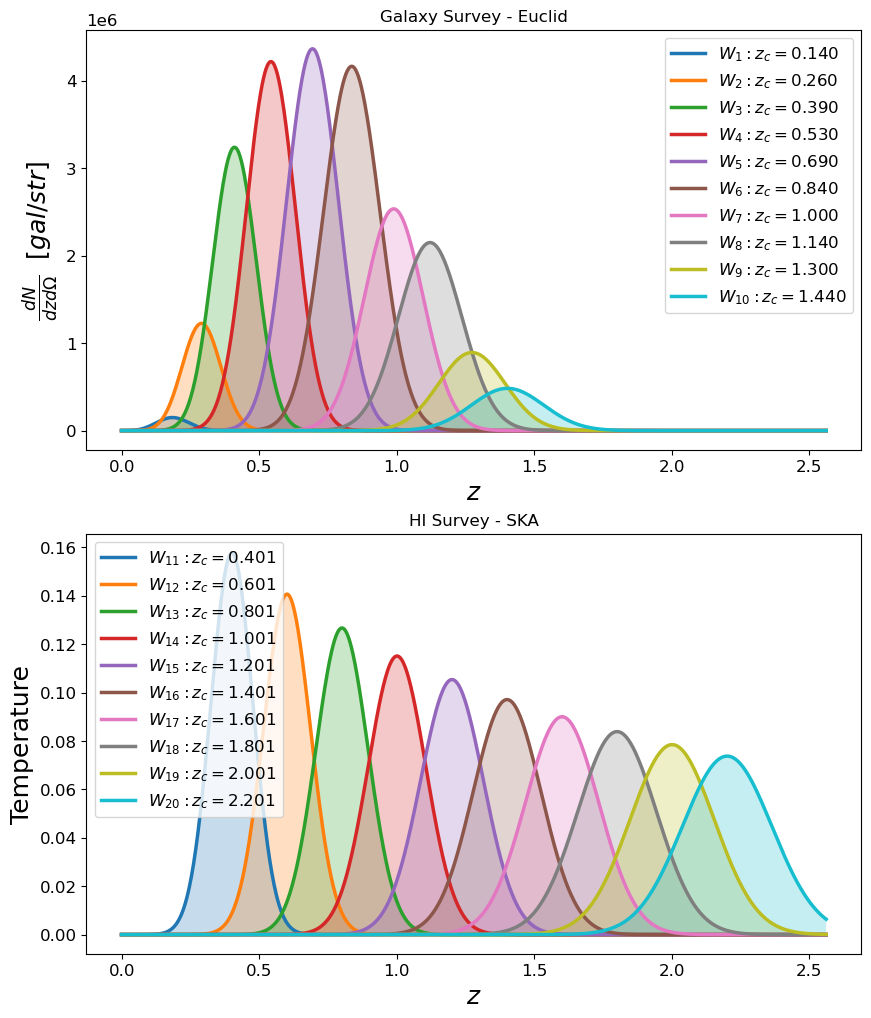

ic| len(Data_arr_zs_full): 210


210

In [72]:
N_bins_Total = N_bins_Gal+N_bins_HI

# Creating central redshifts and redshift combinations
arr_z_central = np.zeros(N_bins_Total)
arr_bin_width = np.zeros(N_bins_Total)
arr_bin_width_nu = np.zeros(N_bins_HI)

for i in range(N_bins_Total):
    if i < N_bins_Gal:
        if Survey_Gal == "Euclid":
            arr_z_central[i] = arr_z_central_Euclid[i]
            arr_bin_width[i] = np.abs(arr_z_central_Euclid[i+1] - arr_z_central_Euclid[i])
        elif Survey_Gal == "DES":
            arr_z_central[i] = arr_z_central_DES[i]
            arr_bin_width[i] = np.abs(arr_z_min_DES[i] - arr_z_max_DES[i])
            # arr_bin_width[i] = np.abs(arr_z_min_long_DES[i] - arr_z_max_long_DES[i])
        elif Survey_Gal == "LSST":
            arr_z_central[i] = arr_z_central_LSST_Y10[i]
            arr_bin_width[i] = bin_width_LSST
    else:
        index_HI = i-N_bins_Gal
        arr_z_central[i] = arr_z_central_HI[index_HI]
        arr_bin_width[i] = bin_width_HI
        nu_1 = nu_ref / ((arr_z_central_HI[index_HI]-bin_width_HI/2) + 1)
        nu_2 = nu_ref / ((arr_z_central_HI[index_HI]+bin_width_HI/2) + 1)
        arr_bin_width_nu[index_HI] =  np.abs( nu_1 - nu_2 )
        # if Survey_HI == "Meerkat":
        #     arr_z_central[i] = arr_z_central_MK[index_HI]
        #     arr_bin_width[i] = bin_width_MK
        #     # arr_bin_width[i] = np.abs(arr_z_central_MK[index_HI] - arr_z_central_MK[index_HI+1])/2
        
        #     arr_bin_width_nu[index_HI] = nu_ref / (bin_width_MK+1) 
        #     # arr_bin_width_nu[index_HI] = np.abs(arr_nu_central_MK[index_HI] - arr_nu_central_MK[index_HI+1])/2 
        # if Survey_HI == "SKA":

ic(arr_bin_width)
ic(arr_bin_width_nu)

# Identify the z-bins of Gal and HI survey
dic_Gal_HI_id  = {}
dic_Gal_HI_id["Gal"] = arr_z_central[:N_bins_Gal]
dic_Gal_HI_id["HI"] = arr_z_central[N_bins_Gal:N_bins_Total]
ic(dic_Gal_HI_id)



# Calculate Window functions
# arr_zs = np.linspace(0, 2, 1000)
arr_zs = np.linspace(0, np.max(arr_z_central) + 2*np.max(arr_bin_width), 1000)

# arr_sigma_z = sigma_val*(1+arr_zs)
arr_sigma_z = np.zeros(N_bins_Total)
for i, z_c in enumerate(arr_z_central):
    if z_c in dic_Gal_HI_id["Gal"]:
        arr_sigma_z[i] = sigma_val
    elif z_c in dic_Gal_HI_id["HI"]:
        arr_sigma_z[i] = arr_bin_width[i]/2

dic_Window  = Window_func_Gal_HI(arr_zs, arr_z_central, z0_value, N_gal_value, 
                                arr_sigma_val=arr_sigma_z, arr_bin_width=arr_bin_width, 
                                arr_n_gal=arr_ngal_bin, func_pz=func_pz, W_func="W_erf",
                                dic_Gal_HI_id=dic_Gal_HI_id, 
                                Show_WS=True, Fig_y_unit="gal/str", 
                                Name_Survey_Gal=Survey_Gal, Name_Survey_HI=Survey_HI, fig_size=(10,12) )
# Bias values 
dic_gal_bias = {}
for i, z_c in enumerate(arr_z_central):

    if z_c in dic_Gal_HI_id["Gal"] and Survey_Gal=="DES":
        dic_gal_bias[z_c] = bias_func_Gal(z_c)
    elif z_c in dic_Gal_HI_id["Gal"]:
        dic_gal_bias[z_c] = arr_bias_gal[i]

    if z_c in dic_Gal_HI_id["HI"] :
        dic_gal_bias[z_c] = bias_HI(z_c)


# Calculate combinations of z-bins
Data_arr_zs_auto= np.zeros((N_bins_Total,2))
Data_arr_zs_full= np.zeros( (int(N_bins_Total*(N_bins_Total+1)/2), 2) )   # The number of elements in a triangular matrix of size n×n is given by the formula n(n+1)​/2
count = 0
for i in range(N_bins_Total):

    z_c_i = arr_z_central[i]
    Data_arr_zs_auto[i] = np.array( [z_c_i, z_c_i] )

    for j in range( N_bins_Total -i ):
        z_c_j = arr_z_central[i+j]  # We do i+j since we don't want to repeat combinations 
        Data_arr_zs_full[count] = np.array( [z_c_i, z_c_j] )
        count+=1


# ic(Data_arr_zs_full)
ic((len(Data_arr_zs_full)))
# ic((Data_arr_zs_full))

Visualise

In [46]:
# arr_zs_vis = np.linspace(0, np.max(dic_Gal_HI_id["Gal"]) + 2*np.max(arr_bin_width), 1000)
# # arr_zs_vis = np.linspace(0, np.max(dic_Gal_HI_id["HI"]) + 3*np.max(arr_bin_width), 1000)

# dic_Window_vis  = Window_func_Gal_HI(arr_zs_vis, arr_z_central, z0_value, N_gal_value, 
#                                 arr_sigma_val=arr_sigma_z, arr_bin_width=arr_bin_width, 
#                                 arr_n_gal=arr_ngal_bin, func_pz=func_pz, W_func="W_erf",
#                                 dic_Gal_HI_id=dic_Gal_HI_id, 
#                                 Show_WS=False)

# plt.figure(figsize=(12,6))   

# for index_zc, z_c in enumerate(arr_z_central):
#     if z_c in dic_Gal_HI_id["Gal"]:
#     # if z_c in dic_Gal_HI_id["HI"]:
#         plt.plot(arr_zs_vis, dic_Window_vis[ z_c ], lw=2.5, label=rF"$W_{{ {index_zc+1} }}: z_c = {z_c :.3f}$")
#         plt.fill_between( arr_zs_vis, dic_Window_vis[ z_c ], y2=np.zeros(len( dic_Window[ z_c ] )), alpha=0.25 )

# plt.xlabel('$z$',fontsize=18)

# plt.ylabel(r"$\frac{dN}{dzd\Omega} \;\;$"+rf"$[gal/str]$",fontsize=18)
# plt.title(f"Galaxy Survey - {Survey_Gal}")
# # plt.ylabel("Temperature",fontsize=18)
# # plt.title(f"HI Survey - {Survey_HI}")

# plt.legend()

# plt.show()

### 1.3 Parameters for $C_\ell$ and $w(\theta)$

In [73]:
# Range of theta and ell values

theta_max = 90
# theta_max = 18

#coupled
l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] )
#decoupled
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +10
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +20


l_max = 1000

theta_min = 180/l_max
theta_min_str = str(round(theta_min, 2))[0] + str(round(theta_min, 2))[2:]

ic(theta_min, theta_max) 
ic(l_min, l_max)

########################################################## Parameters for C_ell and w(theta) #############################
full_l_min = 2
full_l_max = 1000
ell_step = 10
ells = np.arange(full_l_min, full_l_max+1, ell_step)
ic(len(ells))


theta_val = theta_min
theta_step = 0.9
N_thetas = int((theta_max - theta_min)/theta_step) +1
ic(N_thetas)
thetas = np.empty( N_thetas )
count=0

while theta_val < theta_max:
    thetas[count] = theta_val
    theta_val += theta_step
    count+=1

Pol_Legend = np.zeros( (N_thetas, len(ells))  )
for index_t, teta in enumerate(thetas):
    for index_l, l in enumerate(ells):
        Pol_Legend[index_t,index_l] = sc.special.lpmv(0, l, np.cos( np.radians(teta) ))

ic| theta_min: 0.18, theta_max: 90
ic| l_min: np.int64(2), l_max: 1000
ic| len(ells): 100
ic| N_thetas: 100


### 1.4 Cosmology and Magnification bias values

In [74]:
# set_name = "beta"
set_name = "sz"

############################# Cosmological parameters ####################################
# dic_Cosm_param={"parameter_name" : ["par_info", fiducial_value, h_value]
dic_Cosm_param= {
                  "H0"        : ['hubble_const' , 67.27           , 0.7       ],    # H = 100 h    km s-1 Mpc-1
                  'w'         : ['w'            , -1              , 0.05      ],
                  'Ob'        : ['omega_baryon' , 0.0492          , 10**-4    ],
                  'Ocdm'      : ['omega_cdm'    , 0.2647          , 10**-3    ], 
                  "As"        : ["curv_amp"     , 2.2065          , 10**-2    ],    # comoving curvature power at k=pivot_scalar
                  "ns"        : ["spec_index"   , 0.9645          , 10**-2    ]     # scalar spectral index
                  }


# Magnification bias values, s(z)
dic_mag_bias = {}
for index_zc, z_c in enumerate(arr_z_central):
    if z_c in dic_Gal_HI_id["Gal"]:
        if Survey_Gal=="Euclid":
            dic_mag_bias[z_c] = arr_mag_bias_Euclid[index_zc]
        else:
            dic_mag_bias[z_c] = mag_bias_DES(z_c)

    elif z_c in dic_Gal_HI_id["HI"]:
        dic_mag_bias[z_c] = 2/5


# if set_name=="sz":
for index_zc, z_c in enumerate(arr_z_central):
    dic_Cosm_param[f"s_{index_zc+1}"] = ["mag_bias", dic_mag_bias[z_c], dic_mag_bias[z_c]*10**-2]
    if index_zc>=N_bins_Gal-1:
        break

ic(dic_Cosm_param)


dic_cosmology = {
    'Omega_M': dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1], 
    'Omega_b': dic_Cosm_param["Ob"][1],
    "Omega_cdm" : dic_Cosm_param["Ocdm"][1],
    'Omega_L': 1-(dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1]),
    "H_0":dic_Cosm_param["H0"][1],  
    'h': dic_Cosm_param["H0"][1]/100,
    'w': dic_Cosm_param["w"][1],
    "A_s": dic_Cosm_param["As"][1] *10**-9,
    'n_s': dic_Cosm_param["ns"][1],
    'sigma_8': 0.8
    }

pars = camb.CAMBparams()
pars.set_cosmology(H0=dic_cosmology["H_0"], 
                ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
pars.set_dark_energy( w=dic_cosmology["w"] )
pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])


# folder to save the data in
folder_name = "Fisher_Data/"
# String name to save file
save_filename = f"{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_{set_name}"
print(f"{folder_name}_..._{save_filename}_lmin{l_min}_thetaMax{theta_max}")

Fisher_Data/_..._Euclid_10zbins_SKA_10zbins_sz_lmin2_thetaMax90


ic| dic_Cosm_param: {'As': ['curv_amp', 2.2065, 0.01],
                     'H0': ['hubble_const', 67.27, 0.7],
                     'Ob': ['omega_baryon', 0.0492, 0.0001],
                     'Ocdm': ['omega_cdm', 0.2647, 0.001],
                     'ns': ['spec_index', 0.9645, 0.01],
                     's_1': ['mag_bias', np.float64(0.023), np.float64(0.00023)],
                     's_10': ['mag_bias', np.float64(0.787), np.float64(0.00787)],
                     's_2': ['mag_bias', np.float64(0.135), np.float64(0.00135)],
                     's_3': ['mag_bias', np.float64(0.248), np.float64(0.00248)],
                     's_4': ['mag_bias', np.float64(0.253), np.float64(0.00253)],
                     's_5': ['mag_bias', np.float64(0.227), np.float64(0.0022700000000000003)],
                     's_6': ['mag_bias', np.float64(0.28), np.float64(0.0028000000000000004)],
                     's_7': ['mag_bias', np.float64(0.392), np.float64(0.00392)],
                     's_8':

## 2. Covariance Matrix

In [75]:
dic_C_ell_CAMB = C_ells_CAMB_HI(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                pars_CAMB=pars, dic_Gal_HI_id=dic_Gal_HI_id )

In [76]:
# Cov_Matrix_auto = Fisher_CovM_HI_Gal(Data_arr_zs_auto, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, dic_mag_bias, C_ells_CAMB_HI, 
#                               S_area=Omega_surv, N_dishes=N_dishes, time_total=tobs, f_sky=f_sky, arr_bin_width_nu=arr_bin_width_nu, dic_T_sys=dic_T_sys,
#                               bias_func_Gal=gal_bias_Euclid, bias_func_HI=bias_HI, dic_Gal_HI_id=dic_Gal_HI_id,
#                               pars_CAMB=pars)

# Visualizing_Cov_Matrix(Data_arr_zs_auto, l_min, l_max, Cov_Matrix_auto)

In [77]:
Cov_Matrix_full = Fisher_CovM_HI_Gal(Data_arr_zs_full, arr_z_central, dic_Window, full_l_min, full_l_max, 
                                     dic_C_ell_CAMB, dic_f_sky, dic_Gal_HI_id,
                                     ell_step=ell_step, N_dishes=N_dish, D_dish=D_dish, time_total=t_tot, 
                                     arr_bin_width_nu=arr_bin_width_nu, dic_T_sys=dic_T_sys,
                                     verbose=True)

### Saving data
np.save(F"{folder_name}FisherM_CovM_full_{save_filename}", Cov_Matrix_full)
# np.save(F"{folder_name}FisherM_CovM_full_{save_filename}_lmin{l_min}_thetaMax{theta_max}", Cov_Matrix_full)

# Visualizing_Cov_Matrix(Data_arr_zs_full, l_min, l_max, Cov_Matrix_full)

Computing small covariance matrix 1 of 44100
Computing small covariance matrix 8821 of 44100
Computing small covariance matrix 17641 of 44100
Computing small covariance matrix 26461 of 44100
Computing small covariance matrix 35281 of 44100
Cov Matrix Calculated!


## 3. Derivatives

In [78]:
# dic_derivatives_auto = Fisher_derivative_HI(Data_arr_zs_auto, arr_zs, dic_Window, full_l_min, full_l_max, 
#                                             dic_mag_bias, dic_Cosm_param, C_ells_CAMB_HI,
#                                             bias_func_Gal=gal_bias_DES, bias_func_HI=bias_HI, dic_Gal_HI_id=dic_Gal_HI_id )  

In [79]:

dic_derivatives_full = Fisher_derivative_HI(Data_arr_zs_full, arr_zs, dic_Window, full_l_min, full_l_max, 
                                            dic_mag_bias, dic_gal_bias, dic_Cosm_param, C_ells_CAMB_HI, 
                                            ell_step=ell_step, dic_Gal_HI_id=dic_Gal_HI_id, 
                                            verbose=True )   



### Saving data
# with open(F"{folder_name}FisherM_deriv_full_{save_filename}_lmin{l_min}_thetaMax{theta_max}.pkl", 'wb') as file:
with open(F"{folder_name}FisherM_deriv_full_{save_filename}.pkl", 'wb') as file:
    pickle.dump(dic_derivatives_full, file)

Computing derivatives: H0
Computing derivatives: w
Computing derivatives: Ob
Computing derivatives: Ocdm
Computing derivatives: As
Computing derivatives: ns
Computing derivatives: s_1
Computing derivatives: s_2
Computing derivatives: s_3
Computing derivatives: s_4
Computing derivatives: s_5
Computing derivatives: s_6
Computing derivatives: s_7
Computing derivatives: s_8
Computing derivatives: s_9
Computing derivatives: s_10
Derivatives Calculated!


In [80]:
# # Visualizing_derivatives( Data_arr_zs_auto, l_min, l_max, dic_Cosm_param, dic_derivatives_auto )

# Visualizing_derivatives( Data_arr_zs_full, l_min, l_max, dic_Cosm_param, dic_derivatives_full )

## 4. Fisher Matrix  $C_\ell$

Autocorrelations

In [84]:
# Fish_Cl_auto = Fisher_Matrix_Cl(Data_arr_zs_auto, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
#                                 full_l_min, l_min, full_l_max, l_max, f_sky=f_sky)

# Visualising_F_Matrices( Fish_Cl_auto, dic_Cosm_param, 
#                        list_titles=[r"Fisher Matrix of $C_\ell$, auto",r"Inverse Fisher Matrix of $C_\ell$, auto",
#                                     "Resultant Identity Matrix"])

# # Saving data
# df_Cl_auto = pd.DataFrame(data=Fish_Cl_auto.astype(float))
# df_Cl_auto.to_csv(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
#                   sep=' ', header=False, float_format='%.8g', index=False)

Full-correlations

Builing diagonal Matrix
Computing small Fisher matrix 1 of 44100
Computing small Fisher matrix 8821 of 44100
Computing small Fisher matrix 17641 of 44100
Computing small Fisher matrix 26461 of 44100
Computing small Fisher matrix 35281 of 44100
Computing small Fisher matrix 1 of 256
Computing small Fisher matrix 52 of 256
Computing small Fisher matrix 103 of 256
Computing small Fisher matrix 154 of 256
Computing small Fisher matrix 205 of 256


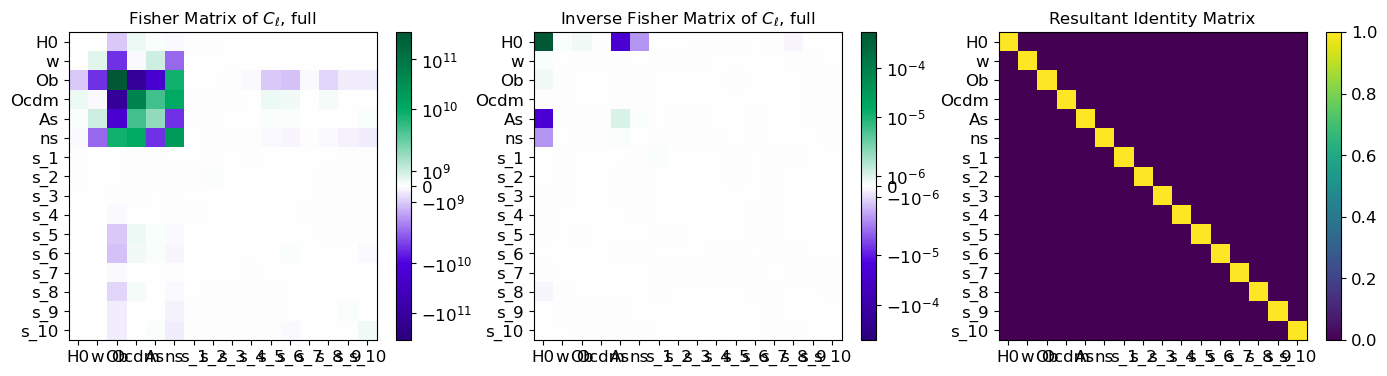

ic| np.sum(Matrix @ Matrix_inv): np.float64(15.999999999967166)


In [85]:
# Loading data
# Cov_Matrix_full = np.load(F"{folder_name}FisherM_CovM_full_{ save_filename}_lmin{l_min}_thetaMax{theta_max}.npy")
Cov_Matrix_full = np.load(F"{folder_name}FisherM_CovM_full_{save_filename}.npy")

# with open(F"{folder_name}FisherM_deriv_full_{save_filename}_lmin{l_min}_thetaMax{theta_max}.pkl", 'rb') as file:
with open(F"{folder_name}FisherM_deriv_full_{save_filename}.pkl", 'rb') as file:
    dic_derivatives_full = pickle.load(file)


# Calculating matrix
Fish_Cl_full = Fisher_Matrix_Cl_test(Data_arr_zs_full, dic_Cosm_param, Cov_Matrix_full, dic_derivatives_full, 
                                full_l_min, l_min, full_l_max, l_max, dic_f_sky, dic_Gal_HI_id=dic_Gal_HI_id,
                                ell_step=ell_step, verbose=True)


# Saving data
df_Cl_full = pd.DataFrame(data=Fish_Cl_full.astype(float))
df_Cl_full.to_csv(F"{folder_name}FisherM_Cl_full_{save_filename}.csv", sep=' ', header=False, float_format='%.8g', index=False)
# df_Cl_full.to_csv(F"{folder_name}FisherM_Cl_full_{save_filename}_lmin{l_min}_thetaMax{theta_max}.csv", 
#                   sep=' ', header=False, float_format='%.8g', index=False)
# Ploting Matrix
Visualising_F_Matrices( Fish_Cl_full, dic_Cosm_param, 
                        list_titles=[r"Fisher Matrix of $C_\ell$, full",r"Inverse Fisher Matrix of $C_\ell$, full",
                                    "Resultant Identity Matrix"])

In [86]:
ic(np.sqrt(np.diagonal(np.linalg.inv(Fish_Cl_full))) )

ic| np.sqrt(np.diagonal(np.linalg.inv(Fish_Cl_full))): array([2.28155390e-02, 1.04344643e-04, 2.09078122e-05, 3.13967807e-05,
                                                              1.02423983e-03, 1.42772421e-04, 3.63342531e-04, 1.39336931e-04,
                                                              1.47581215e-04, 1.43885331e-04, 1.52292420e-04, 1.42254328e-04,
                                                              1.59682576e-04, 1.41614611e-04, 1.28944997e-04, 9.01539238e-05])


array([2.28155390e-02, 1.04344643e-04, 2.09078122e-05, 3.13967807e-05,
       1.02423983e-03, 1.42772421e-04, 3.63342531e-04, 1.39336931e-04,
       1.47581215e-04, 1.43885331e-04, 1.52292420e-04, 1.42254328e-04,
       1.59682576e-04, 1.41614611e-04, 1.28944997e-04, 9.01539238e-05])

Comparar valores 1bins LSST, 1 bin SKA

novo 
array([0.32382974, 0.00802944, 0.0005439 , 0.00097758, 0.00992021,
       0.00105429, 0.00153052])

antigo
array([14.07738233,  0.22470128,  0.01908562,  0.02977622,  0.40454805,
        0.02287852,  0.20803661])

## 5. Fisher Matrix $w(\theta)$

In [102]:
# Fish_w_auto = Fisher_Matrix_w(Data_arr_zs_auto, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
#                               f_sky=f_sky, verbose=True)

# Visualising_F_Matrices( Fish_w_auto, dic_Cosm_param, 
#                        list_titles=[r"Fisher Matrix of $w(\theta)$, auto",r"Inverse Fisher Matrix of $w(\theta)$, auto",
#                                     "Resultant Identity Matrix"])

# # Saving data
# df_w_auto = pd.DataFrame(data=Fish_w_auto.astype(float))
# df_w_auto.to_csv(F"{folder_name}FisherM_w_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
#                  sep=' ', header=False, float_format='%.8g', index=False)

Computing small covariance matrix 1 of 44100
Computing small covariance matrix 8821 of 44100
Computing small covariance matrix 17641 of 44100
Computing small covariance matrix 26461 of 44100
Computing small covariance matrix 35281 of 44100


ic| Big_Matrix.shape: (21000, 21000)
ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(21000.003624940593)
    N_data*N_thetas: 21000


Computing derivatives
Fisher Matrix calculated!


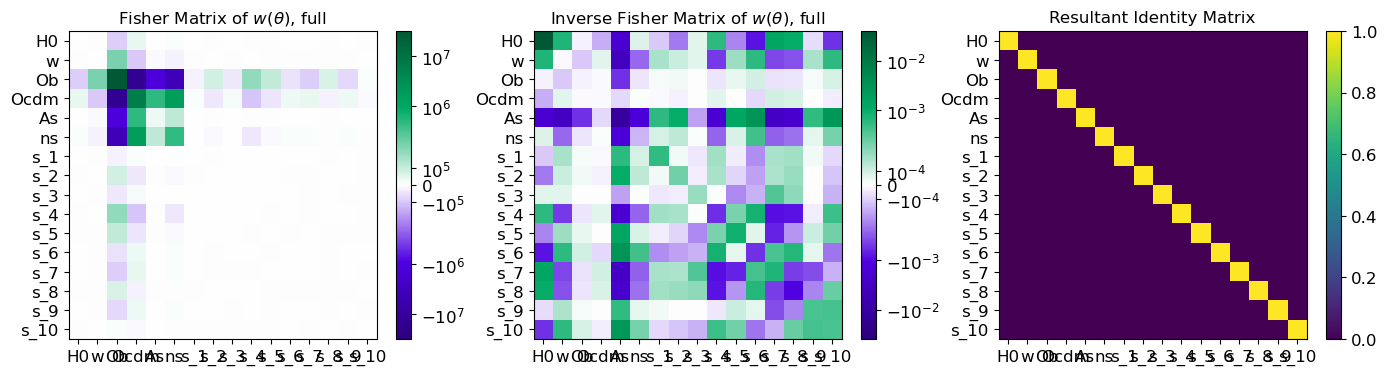

ic| np.sum(Matrix @ Matrix_inv): np.float64(15.999999999998881)


In [26]:
# Loading data
# Cov_Matrix_full = np.load(F"{folder_name}FisherM_CovM_full_{ save_filename}_lmin{l_min}_thetaMax{theta_max}.npy")
Cov_Matrix_full = np.load(F"{folder_name}FisherM_CovM_full_{ save_filename}.npy")

# with open(F"{folder_name}FisherM_deriv_full_{save_filename}_lmin{l_min}_thetaMax{theta_max}.pkl", 'rb') as file:
with open(F"{folder_name}FisherM_deriv_full_{save_filename}.pkl", 'rb') as file:
    dic_derivatives_full = pickle.load(file)

Fish_w_full = Fisher_Matrix_w(Data_arr_zs_full, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_full, 
                              dic_derivatives_full, dic_f_sky, dic_Gal_HI_id=dic_Gal_HI_id, verbose=True)

Visualising_F_Matrices( Fish_w_full, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $w(\theta)$, full",r"Inverse Fisher Matrix of $w(\theta)$, full",
                                    "Resultant Identity Matrix"])

# # Saving data
df_w_full = pd.DataFrame(data=Fish_w_full.astype(float))
df_w_full.to_csv(F"{folder_name}FisherM_w_full_{save_filename}.csv", sep=' ', header=False, float_format='%.8g', index=False)
# df_w_full.to_csv(F"{folder_name}FisherM_w_full_{save_filename}_lmin{l_min}_thetaMax{theta_max}.csv", 
#                  sep=' ', header=False, float_format='%.8g', index=False)

In [27]:
ic(np.diagonal(np.linalg.inv(Fish_w_full)))

ic| np.diagonal(np.linalg.inv(Fish_w_full)): array([ 3.93350966e-02, -1.29449386e-05, -2.62652690e-05, -1.54120311e-05,
                                                    -1.11398543e-02, -1.58914677e-04,  5.36138828e-04,  3.04330277e-04,
                                                     2.16145385e-04, -5.60485522e-04,  8.37158444e-04, -5.57061912e-04,
                                                     6.81963029e-04, -1.04378113e-03,  3.88589043e-04,  3.88836828e-04])


array([ 3.93350966e-02, -1.29449386e-05, -2.62652690e-05, -1.54120311e-05,
       -1.11398543e-02, -1.58914677e-04,  5.36138828e-04,  3.04330277e-04,
        2.16145385e-04, -5.60485522e-04,  8.37158444e-04, -5.57061912e-04,
        6.81963029e-04, -1.04378113e-03,  3.88589043e-04,  3.88836828e-04])

## 6. Visualise **Corner plots** 

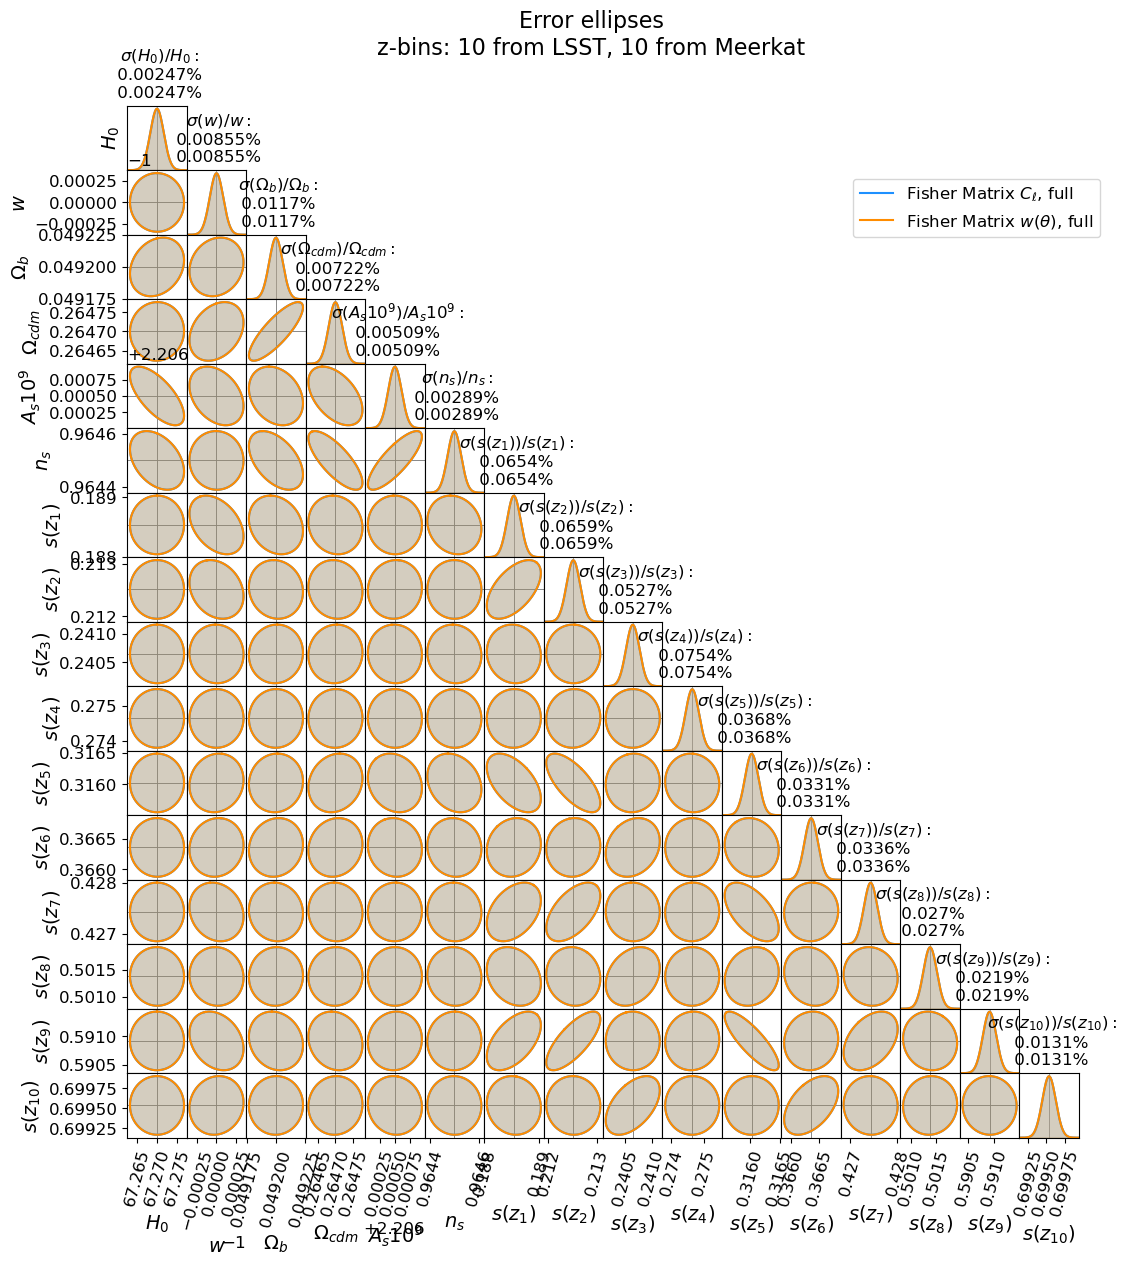

In [25]:
# Importing Fihser Matrices values from  saved data

FIM_Cl_full = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}.csv", "rb"), delimiter=" ", skiprows=0)

########################## Corner plots ###################################################################
fid=[]
# counter = 1
for key in dic_Cosm_param.keys():
    fid.append( dic_Cosm_param[key][1] )
    # if counter > 4:
    #     fid.append( dic_Cosm_param[key][1] )
    # counter+=1

par = [
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$",
    # r"$\beta$",
    r"$s(z_1)$",
    r"$s(z_2)$",
    r"$s(z_3)$",
    r"$s(z_4)$",
    r"$s(z_5)$",
    r"$s(z_6)$",
    r"$s(z_7)$",
    r"$s(z_8)$",
    r"$s(z_9)$",
    r"$s(z_{10})$",
    ]
par_titles = par

# Plot_title = rf"Error Ellipses: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"
Plot_title = ("Error ellipses \n" + 
              rf"z-bins: {N_bins_Gal} from {Survey_Gal}, {N_bins_HI} from {Survey_HI} "  
            #   +"\n"+
            #   rf"$\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$"
              )

# name_fig_corner = f"Figures/CornerP_{set_name}_{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_theta_{theta_min_str}_{theta_max:.3g}-ell_{l_min}_{l_max}"
name_fig_corner = f"Figures/CornerP_{set_name}_{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins"

# list_colors = ["#37b67e", "#057041", "#7e71bf", "#4900ac"]
# list_colors = ["dodgerblue", "darkorange", "slateblue", "firebrick"]
list_colors = ["slateblue", "firebrick", "dodgerblue", "darkorange"]


# Only s(z)
# Fishers = [ np.linalg.inv(np.linalg.inv(FIM_Cl_auto) [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_auto)  [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_Cl_cross)[0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_cross) [0:4,0:4]) ]

# Only Cosm param
# Fishers = [ np.linalg.inv(np.linalg.inv(FIM_Cl_auto) [4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_auto)  [4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_Cl_cross)[4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_cross) [4:,4:]) ]


# Fishers = [ FIM_Cl_auto, FIM_w_auto, FIM_Cl_full, FIM_w_full ]
# Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto", r"Fisher Matrix $C_\ell$, full", r"Fisher Matrix $w(\theta)$, full" ]
# CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, cores=list_colors, figure_size=(10,8), 
#             Fig_name= name_fig_corner+".png")

# Fishers = [ FIM_Cl_auto, FIM_w_auto]
# Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto"  ]
# CornerPlot( Fishers, fid, par, par_titles, Plot_title,  Flabels=Flabels, cores=[list_colors[0], list_colors[1]] )

# Fishers = [ FIM_Cl_full, FIM_w_full ]
# Fishers = [ FIM_w_full, FIM_w_full ]
Fishers = [ FIM_Cl_full, FIM_Cl_full ]
Flabels = [ r"Fisher Matrix $C_\ell$, full", r"Fisher Matrix $w(\theta)$, full" ]
CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, cores=[list_colors[2], list_colors[3]], 
            Fig_name= name_fig_corner+"_full.png", figure_size=(11,12))

## 7. Compare performance with **histograms**

ic| check_parameters: ['H0',
                       'w',
                       'Ob',
                       'Ocdm',
                       'As',
                       'ns',
                       's_1',
                       's_2',
                       's_3',
                       's_4',
                       's_5',
                       's_6',
                       's_7',
                       's_8',
                       's_9',
                       's_10']


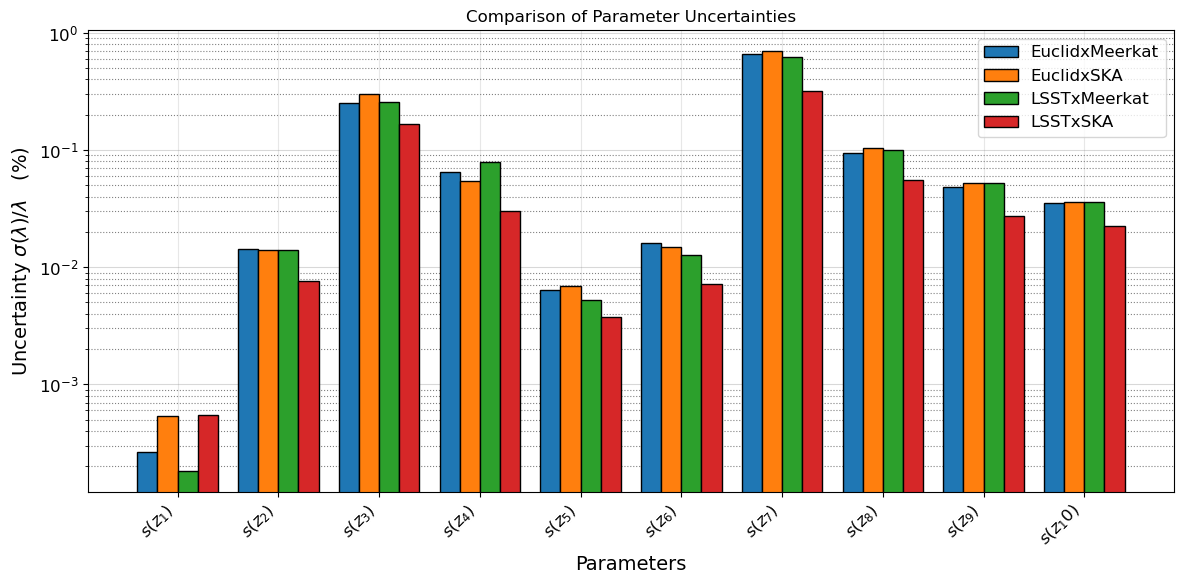

In [90]:
list_parameters = [
    # r'$H_0$',
    # r'$w$', 
    # r"$\Omega_b$", 
    # r"$\Omega_{cdm}$",
    # r"$A_s 10^{9}$", 
    # r"$n_s$",
    # r"$\beta$",
    r"$s(z_1)$",
    r"$s(z_2)$",
    r"$s(z_3)$",
    r"$s(z_4)$",
    r"$s(z_5)$",
    r"$s(z_6)$",
    r"$s(z_7)$",
    r"$s(z_8)$",
    r"$s(z_9)$",
    r"$s(z_10)$",
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )
ic(check_parameters)

skip_Cosm_param = 6


# list_Gal_surv = ["Euclid", "DES", "LSST"]
list_Gal_surv = ["Euclid", "LSST"]
list_HI_surv  = ["Meerkat", "SKA"]


dic_Result_Surveys = {}

for Name_Survey_Gal in list_Gal_surv:
    for Name_Survey_HI in list_HI_surv:

        save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
        # Load your Fisher matrices
        FIM_Cl_full_i = np.loadtxt(open(f"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
        # Calculate parameter uncertainties (sqrt of diagonal of inverse FIM)
        Inv_FIM_Cl_full_i = np.linalg.inv(FIM_Cl_full_i)
        
        array_FIM_err_percent = np.zeros( len(list_parameters) )
        for index_p in range(len(list_parameters)):
            array_FIM_err_percent[index_p] = np.sqrt( Inv_FIM_Cl_full_i [index_p+skip_Cosm_param,index_p+skip_Cosm_param] 
                                                     ) / np.abs(parameters_vals[index_p]) * 100
        
        dic_Result_Surveys[f"{Name_Survey_Gal}x{Name_Survey_HI}"] = array_FIM_err_percent

        # ax.bar(x - width/2, dic_Result_Surveys[f"{Name_Survey_Gal}x{Name_Survey_HI}"], width, label=f'{Name_Survey_HI} x {Name_Survey_Gal}')

list_keys= []
for key in dic_Result_Surveys.keys():
    list_keys.append(key)


# Ploting 
fig, ax = plt.subplots(figsize=(12, 6))

# list_colors = ["slateblue", "firebrick", "dodgerblue", "darkorange"]

width=0.2
# width = 0.35
Label_loc = np.arange(len(list_parameters))
counter = 0
for key in list_keys:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, dic_Result_Surveys[key], width, label=key, 
                #    color=list_colors[counter], 
                   edgecolor="k")
    counter += 1

ax.set_xlabel('Parameters')
ax.set_ylabel(r'Uncertainty $\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title('Comparison of Parameter Uncertainties')
# ax.set_xticks(x)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_xticklabels(list_parameters, rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")

plt.tight_layout()
plt.show()

#### Baseline

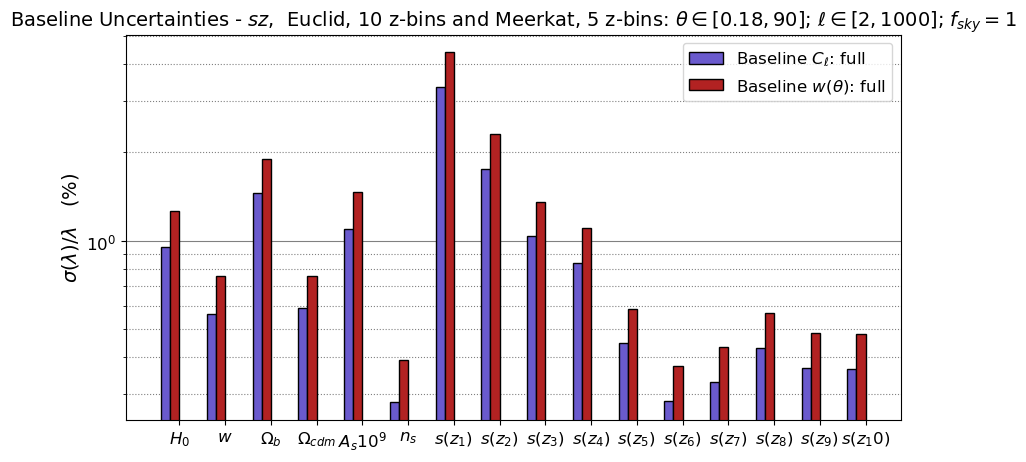

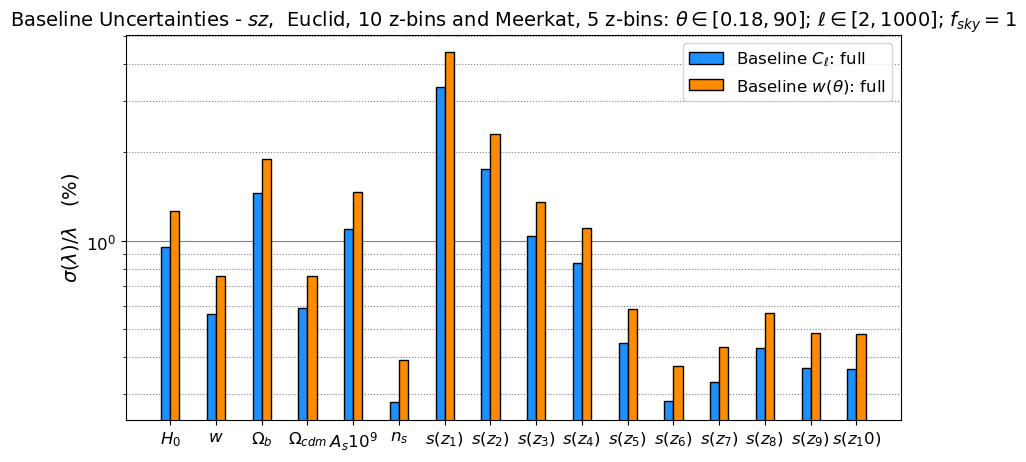

In [ ]:
# FIM_Cl_auto_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_w_auto_Base  = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_full_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_full_Base  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)

# Inv_FIM_Cl_auto_Base = np.linalg.inv( FIM_Cl_auto_Base)
# Inv_FIM_w_auto_Base  = np.linalg.inv( FIM_w_auto_Base )    
Inv_FIM_Cl_full_Base = np.linalg.inv( FIM_Cl_full_Base)  
Inv_FIM_w_full_Base  = np.linalg.inv( FIM_w_full_Base )  

Title_plot = rf"Baseline Uncertainties - ${set_name}$,  {Survey_Gal}, {N_bins_Gal} z-bins and {Survey_HI}, {N_bins_HI} z-bins: $\theta \in [{0.18}, {90}]$; $\ell \in [{2}, {1000}]$; " + r"$f_{sky} = 1$"  
name_fig_hist_base = f"Figures/Hist_{set_name}_{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_theta_018_90-ell_2_1000-f_sky_10"

list_parameters = [
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$",
    # r"$\beta$",
    r"$s(z_1)$",
    r"$s(z_2)$",
    r"$s(z_3)$",
    r"$s(z_4)$",
    r"$s(z_5)$",
    r"$s(z_6)$",
    r"$s(z_7)$",
    r"$s(z_8)$",
    r"$s(z_9)$",
    r"$s(z_10)$",
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )

array_Cl_auto_Base = np.zeros( len(list_parameters) )
array_w_auto_Base  = np.zeros( len(list_parameters) )
array_Cl_full_Base = np.zeros( len(list_parameters) )
array_w_full_Base  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    # array_Cl_auto_Base[index_p] = np.sqrt( Inv_FIM_Cl_auto_Base [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    # array_w_auto_Base[index_p]  = np.sqrt( Inv_FIM_w_auto_Base [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full_Base[index_p] = np.sqrt( Inv_FIM_Cl_full_Base [index_p,index_p] ) / np.abs(p) * 100
    array_w_full_Base[index_p]  = np.sqrt( Inv_FIM_w_full_Base [index_p,index_p] )  / np.abs(p) * 100

Est_Result_dic_Base = { }
# Est_Result_dic_Base[r"Baseline $C_\ell$: auto"]    = array_Cl_auto_Base
# Est_Result_dic_Base[r"Baseline $w(\theta)$: auto"]= array_w_auto_Base
Est_Result_dic_Base[r"Baseline $C_\ell$: full"]    = array_Cl_full_Base
Est_Result_dic_Base[r"Baseline $w(\theta)$: full"] = array_w_full_Base

list_Base_keys= []
for key in Est_Result_dic_Base.keys():
    list_Base_keys.append(key)

# Ploting 
fig, ax = plt.subplots(figsize=(10,5))

list_colors = ["slateblue", "firebrick", "dodgerblue", "darkorange"]

width=0.2
Label_loc = np.arange(len(list_parameters))
counter = 0
for key in list_Base_keys:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_Base[key], width, label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist_base+".png")
plt.show()


########################## Plotting only Full correlations ##############################

Est_Result_dic_Base_full = { }
Est_Result_dic_Base_full[r"Baseline $C_\ell$: full"]    = array_Cl_full_Base
Est_Result_dic_Base_full[r"Baseline $w(\theta)$: full"] = array_w_full_Base

list_Base_keys_full= []
for key in Est_Result_dic_Base_full.keys():
    list_Base_keys_full.append(key)

fig, ax = plt.subplots(figsize=(10,5))

list_colors_full = ["dodgerblue", "darkorange" ]
counter = 0
for key in list_Base_keys_full:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_Base_full[key], width, 
                   label=key, color=list_colors_full[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 0.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist_base+"_full.png")
plt.show()

#### Parameters to compare Baseline with

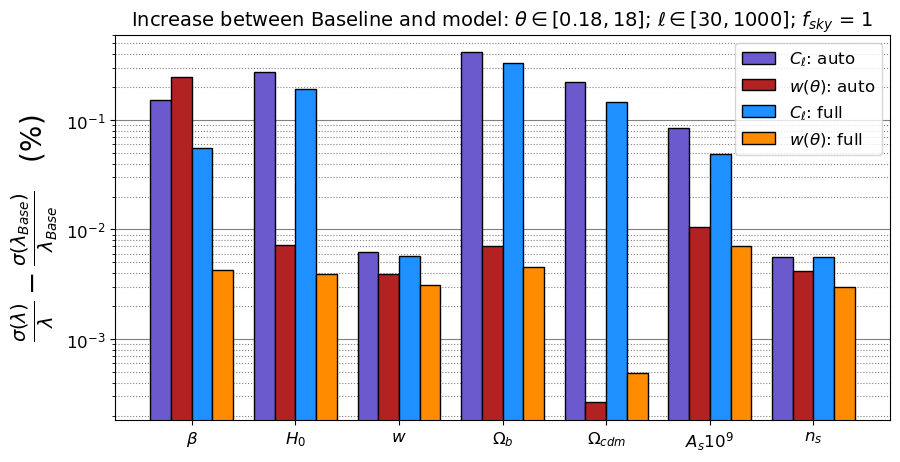

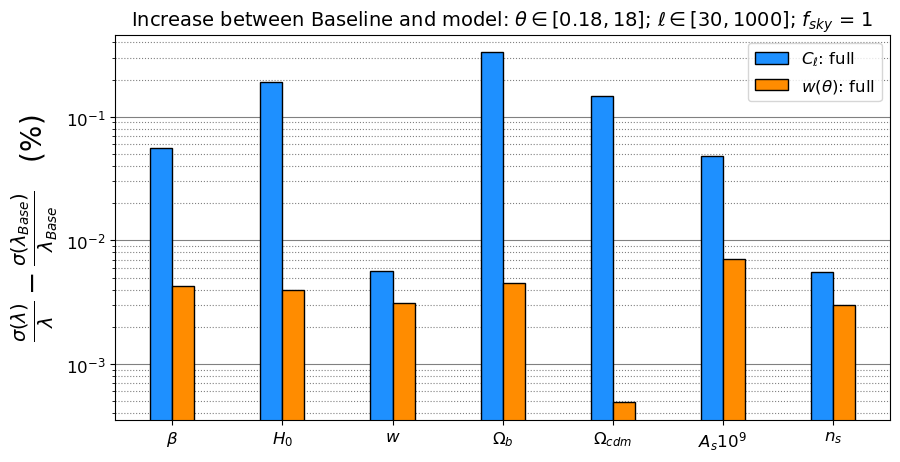

In [ ]:
# f_sky, f_sky_str = 1.0, "10"
# f_sky, f_sky_str = 0.33, "033"

# theta_max = 18

# l_min     = 10
# l_min     = 30


FIM_Cl_auto = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto  = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_full = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)

Inv_FIM_Cl_auto = np.linalg.inv( FIM_Cl_auto )
Inv_FIM_w_auto  = np.linalg.inv( FIM_w_auto  )    
Inv_FIM_Cl_full = np.linalg.inv( FIM_Cl_full)  
Inv_FIM_w_full  = np.linalg.inv( FIM_w_full )  


Title_plot = rf"Increase between Baseline and model: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"  

name_fig_hist = f"Figures/Hist_{set_name}_{Survey}_{N_bins}z-bins_theta_{theta_min_str}_{theta_max:.3g}-ell_{l_min}_{l_max}-f_sky_{f_sky_str}"


list_parameters = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )


array_Cl_auto = np.zeros( len(list_parameters) )
array_w_auto  = np.zeros( len(list_parameters) )
array_Cl_full = np.zeros( len(list_parameters) )
array_w_full  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    array_Cl_auto[index_p] = np.sqrt( Inv_FIM_Cl_auto [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    array_w_auto[index_p]  = np.sqrt( Inv_FIM_w_auto [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full[index_p] = np.sqrt( Inv_FIM_Cl_full [index_p,index_p] ) / np.abs(p) * 100
    array_w_full[index_p]  = np.sqrt( Inv_FIM_w_full [index_p,index_p] )  / np.abs(p) * 100

Est_Result_dic = { }
Est_Result_dic[r"$C_\ell$: auto"]    = array_Cl_auto
Est_Result_dic[r"$w(\theta)$: auto"] = array_w_auto
Est_Result_dic[r"$C_\ell$: full"]    = array_Cl_full
Est_Result_dic[r"$w(\theta)$: full"] = array_w_full

# Ploting 
fig, ax = plt.subplots(figsize=(10,5))

width=0.2
Label_loc = np.arange(len(list_parameters))
counter = 0
for index_key, key in enumerate(Est_Result_dic.keys()):
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic[key]-Est_Result_dic_Base[list_Base_keys[index_key]], width, 
                   label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\frac{\sigma(\lambda)}{\lambda} - \frac{\sigma(\lambda_{Base})}{\lambda_{Base}}  \quad (\%)$', fontsize=20)
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist+".png")
plt.show()



########################## Plotting only Full correlations ##############################

Est_Result_dic_full = { }
Est_Result_dic_full[r"$C_\ell$: full"]    = array_Cl_full
Est_Result_dic_full[r"$w(\theta)$: full"] = array_w_full


fig, ax = plt.subplots(figsize=(10,5))

list_colors_full = ["dodgerblue", "darkorange" ]
counter = 0
for index_key, key in enumerate(Est_Result_dic_full.keys()):
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_full[key]-Est_Result_dic_Base_full[list_Base_keys_full[index_key]], width, 
                   label=key, color=list_colors_full[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\frac{\sigma(\lambda)}{\lambda} - \frac{\sigma(\lambda_{Base})}{\lambda_{Base}}  \quad (\%)$', fontsize=20)
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 0.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist+"_full.png")
plt.show()